
# IS630: Green Light for an Indie Studio
## Notebook 03: AQ2, Can We Predict Success?
**Group**: [Insert names]

> **AI Coding Assistant Declaration**:
> In accordance with course guidelines, an AI coding assistant was used strictly for code scaffolding and plotting functions. All code blocks below are labeled as AI-assisted. All modelling decisions, interpretations, and written commentaries are independently authored by group members in the designated sections below.

This notebook works through one data question per section, building towards **AQ3**

- Baseline that predicts the mean
- Frequentist model, standard errors clustered by developer (form to decide: OLS or binomial GLM)
- Diagnostics: residuals, VIF
- Bayesian hierarchical model in PyMC, priors stated
- Convergence checks and posterior predictive check
- Prior sensitivity
- Compare baseline, frequentist and Bayesian on validation
- Completion ratio model, if kept as a target

*Outline written by AI Assistant*

### 1.1 Baseline Model

A baseline model is established to provide a reference point for evaluating subsequent statistical models.

The baseline predicts the same positive review rate for every game, calculated as the mean positive review rate among reception-eligible games in the development-training dataset.

Predictions are evaluated against the validation dataset using Mean Absolute Error (MAE) and Root Mean Squared Error (RMSE). These metrics measure the differences between predicted and observed positive review rates, with lower values indicating better predictive accuracy.

The baseline uses only development-training observations to calculate its prediction, ensuring that validation data does not influence model fitting.

This provides a benchmark for determining whether the frequentist and Bayesian models offer improvements in predictive performance.

In [2]:

# Step 1: Import libraries and load model-ready datasets

import sys
import json
from pathlib import Path
import matplotlib.pyplot as plt

import numpy as np
import pandas as pd
from IPython.display import display

# Locate project root
ROOT = next(
    p for p in [Path.cwd(), *Path.cwd().parents]
    if (p / "src" / "is630").exists()
)

sys.path.insert(0, str(ROOT / "src"))

from is630 import config

# Ensure figure output directory exists
config.FIGURES.mkdir(parents=True, exist_ok=True)

# Load outputs from Notebook 02
train_path = config.PROCESSED / "02_train.parquet"
val_path = config.PROCESSED / "02_validation.parquet"
spec_path = config.PROCESSED / "02_feature_spec.json"

df_train = pd.read_parquet(train_path)
df_val = pd.read_parquet(val_path)

with open(spec_path, "r", encoding="utf-8") as f:
    feature_spec = json.load(f)

MODEL_FEATURES = feature_spec["model_features"]

print("Datasets loaded successfully.\n")

print("Development training:", df_train.shape)
print("Validation:", df_val.shape)

print("\nNumber of model predictors:", len(MODEL_FEATURES))

# Verify required predictors
for dataset in [df_train, df_val]:
    missing = set(MODEL_FEATURES) - set(dataset.columns)
    assert not missing, f"Missing predictors: {missing}"

# Verify no overlap between datasets
assert set(df_train["steam_appid"]).isdisjoint(
    set(df_val["steam_appid"])
)

print("\nDataset loading checks passed.")


Datasets loaded successfully.

Development training: (76557, 145)
Validation: (19140, 145)

Number of model predictors: 35

Dataset loading checks passed.


In [3]:

# Step 1: Build and evaluate the mean baseline model

# Select reception-eligible observations
train_reception = df_train.loc[
    df_train["flag_reception_model"]
].copy()

val_reception = df_val.loc[
    df_val["flag_reception_model"]
].copy()

# Calculate baseline prediction from training data only
baseline_mean = train_reception[
    "steam_positive_rate"
].mean()

# Predict the same value for every validation game
val_reception["baseline_prediction"] = baseline_mean

# Actual observed positive review rates
y_true = val_reception["steam_positive_rate"].to_numpy()

# Baseline predictions
y_pred = val_reception["baseline_prediction"].to_numpy()

# Calculate evaluation metrics
baseline_mae = np.mean(
    np.abs(y_true - y_pred)
)

baseline_rmse = np.sqrt(
    np.mean((y_true - y_pred) ** 2)
)

# Summarize baseline performance
baseline_results = pd.DataFrame({
    "Model": ["Mean Baseline"],
    "Training Games": [len(train_reception)],
    "Validation Games": [len(val_reception)],
    "Baseline Prediction": [baseline_mean],
    "Validation MAE": [baseline_mae],
    "Validation RMSE": [baseline_rmse]
})

display(baseline_results.round(4))

# Save baseline model results
config.TABLES.mkdir(parents=True, exist_ok=True)

baseline_results.to_csv(
    config.TABLES / "03_q1_reception_baseline.csv",
    index=False
)


print("Baseline results table saved successfully.")

# Validation checks
assert len(train_reception) == df_train["flag_reception_model"].sum()
assert len(val_reception) == df_val["flag_reception_model"].sum()

assert train_reception["steam_review_count"].ge(10).all()
assert val_reception["steam_review_count"].ge(10).all()


assert 0 <= baseline_mean <= 1
assert np.isfinite(baseline_mae)
assert np.isfinite(baseline_rmse)

print("\nBaseline model checks passed.")


,Model,Training Games,Validation Games,Baseline Prediction,Validation MAE,Validation RMSE
0,Mean Baseline,34935,8734,0.7737,0.1411,0.1769


Baseline results table saved successfully.

Baseline model checks passed.


### 1.2 Frequentist Statistical Modelling

A Binomial Generalized Linear Model (GLM) with a logit link function is used to examine whether game characteristics can predict positive Steam review rates.

Unlike the baseline model, the GLM incorporates the 12 predictors prepared in Notebook 02, including genre indicators, price, game age, and language support. Positive and negative review counts are modelled directly, allowing games with more reviews to contribute greater statistical information.

Developer-level clustering is applied to the standard errors to account for potential dependence between games produced by the same developer. Where developer information is unavailable, observations are treated as separate clusters rather than grouping all missing values together.

The model is fitted using the development-training dataset and evaluated using the validation dataset. Predictive performance is assessed using Mean Absolute Error (MAE) and Root Mean Squared Error (RMSE), consistent with the baseline evaluation.

The resulting regression coefficients and odds ratios will be examined to understand associations between game characteristics and positive review rates. Model assumptions and potential overdispersion will be investigated in the subsequent diagnostics section.

In [4]:

# Step 2: Prepare developer groups for clustered standard errors

import ast

# Verify developer information exists
assert "steam_developers" in train_reception.columns


from is630.features import extract_primary_developer

# Create developer groups using the shared function
train_reception["developer_group"] = extract_primary_developer(
    train_reception["steam_developers"],
    train_reception["steam_appid"]
)


# Summarize developer groups
developer_counts = (
    train_reception["developer_group"].value_counts()
)

print("Developer grouping completed.\n")

print("Training games:", len(train_reception))
print("Unique developer groups:", len(developer_counts))
print("Developer groups with multiple games:",
      (developer_counts > 1).sum())

print("\nTop 10 developer groups:")
display(developer_counts.head(10))

# Validation
assert train_reception["developer_group"].notna().all()

assert len(train_reception) == df_train["flag_reception_model"].sum()


print("\nDeveloper grouping checks passed.")


Developer grouping completed.

Training games: 34935
Unique developer groups: 22657
Developer groups with multiple games: 5065

Top 10 developer groups:


developer_group
choice of games             93
koei tecmo games co.        75
sokpop collective           68
laush dmitriy sergeevich    67
gamesforgames               63
square enix                 58
dnovel                      57
hosted games                50
tero lunkka                 48
creobit                     46
Name: count, dtype: int64


Developer grouping checks passed.


In [6]:

# Step 2: Fit Model 1A — Unweighted Fractional Logit

import statsmodels.api as sm

# Prepare model predictors
X_train_fractional = sm.add_constant(
    train_reception[MODEL_FEATURES].astype(float),
    has_constant="add"
)

# Exclude the constant predictor from Model 1A estimation
X_train_fractional = X_train_fractional.drop(
    columns=["flag_missing_tags"]
)

# Verify full column rank
assert np.linalg.matrix_rank(
    X_train_fractional.to_numpy()
) == X_train_fractional.shape[1]


# Use observed positive review rates
y_train_fractional = train_reception[
    "steam_positive_rate"
].astype(float)

# Fit unweighted fractional logit
fractional_model = sm.GLM(
    y_train_fractional,
    X_train_fractional,
    family=sm.families.Binomial()
)

fractional_fit = fractional_model.fit(
    maxiter=100,
    cov_type="cluster",
    cov_kwds={
        "groups": train_reception["developer_group"].to_numpy()
    }
)

print("Unweighted Fractional Logit fitted successfully.\n")
print("Model converged:", fractional_fit.converged)
print("Training observations:", int(fractional_fit.nobs))
print("Predictors:", X_train_fractional.shape[1] - 1)

# Summarize coefficients and clustered standard errors
fractional_summary = pd.DataFrame({
    "Coefficient": fractional_fit.params,
    "Clustered SE": fractional_fit.bse,
    "P-value": fractional_fit.pvalues
})

display(fractional_summary.round(4))

# Save model summary
config.TABLES.mkdir(parents=True, exist_ok=True)

fractional_summary.to_csv(
    config.TABLES / "03_q2_fractional_logit_coefficients.csv"
)

# Validation checks
assert fractional_fit.converged
assert int(fractional_fit.nobs) == len(train_reception)
assert np.isfinite(fractional_fit.params).all()
assert np.isfinite(fractional_fit.bse).all()

print("\nFractional Logit model checks passed.")


Unweighted Fractional Logit fitted successfully.

Model converged: True
Training observations: 34935
Predictors: 34


,Coefficient,Clustered SE,P-value
const,1.6711,0.1127,0.0000
feature_log_price,0.0691,0.0225,0.0022
flag_free_to_play,0.1407,0.0411,0.0006
steam_years_since_release,-0.0660,0.0031,0.0000
flag_q4_release,0.0690,0.0127,0.0000
steam_mac,0.1713,0.0193,0.0000
steam_linux,0.0706,0.0277,0.0107
feature_log_language_count_imputed,-0.0614,0.0142,0.0000
feature_language_missing,-0.3777,0.3402,0.2668
feature_log_audio_language_count,0.0885,0.0204,0.0000



Fractional Logit model checks passed.


In [5]:

# Diagnose singular matrix in Model 1A

X_diagnostic = X_train_fractional

# Check matrix rank
matrix_rank = np.linalg.matrix_rank(
    X_diagnostic.to_numpy()
)

print("Total matrix columns:", X_diagnostic.shape[1])
print("Matrix rank:", matrix_rank)

print(
    "Rank deficiency:",
    X_diagnostic.shape[1] - matrix_rank
)

# Identify constant predictors
constant_features = [
    col for col in MODEL_FEATURES
    if X_diagnostic[col].nunique() <= 1
]

print("\nConstant predictors:", constant_features)

# Check numerical stability
singular_values = np.linalg.svd(
    X_diagnostic.to_numpy(),
    compute_uv=False
)

print(
    "\nSmallest singular values:",
    singular_values[-5:]
)


Total matrix columns: 36
Matrix rank: 35
Rank deficiency: 1

Constant predictors: ['flag_missing_tags']

Smallest singular values: [2.43118402e+01 1.45352354e+01 7.62945706e+00 5.16145403e+00
 7.18372476e-15]


In [7]:

# Step 2: Fit Binomial GLM with developer-clustered standard errors

import statsmodels.api as sm

# Use the same estimable predictors as Model 1A
X_train = train_reception[
    X_train_fractional.columns.drop("const")
].astype(float)


# Add intercept
X_train = sm.add_constant(
    X_train,
    has_constant="add"
)

# Prepare positive and negative review counts
y_counts = train_reception[
    ["steam_positive", "steam_negative"]
].astype(float)

# Verify valid Binomial observations
assert y_counts.notna().all().all()
assert (y_counts >= 0).all().all()
assert (y_counts.sum(axis=1) > 0).all()

# Check predictor matrix rank
assert np.linalg.matrix_rank(X_train.to_numpy()) == X_train.shape[1]

# Specify Binomial GLM
glm_model = sm.GLM(
    y_counts.to_numpy(),
    X_train,
    family=sm.families.Binomial()
)

# Fit with clustered standard errors
glm_fit = glm_model.fit(
    maxiter=100,
    cov_type="cluster",
    cov_kwds={
        "groups": train_reception["developer_group"].to_numpy()
    }
)

print("Binomial GLM fitted successfully.\n")

print("Model converged:", glm_fit.converged)
print("Number of observations:", glm_fit.nobs)

# Display regression coefficients
coefficient_summary = pd.DataFrame({
    "Coefficient": glm_fit.params,
    "Clustered SE": glm_fit.bse,
    "Odds Ratio": np.exp(glm_fit.params),
    "P-value": glm_fit.pvalues
})

display(coefficient_summary.round(4))

assert glm_fit.converged

print("\nGLM fitting checks passed.")


Binomial GLM fitted successfully.

Model converged: True
Number of observations: 34935


,Coefficient,Clustered SE,Odds Ratio,P-value
const,0.8181,0.3169,2.2661,0.0098
feature_log_price,0.1028,0.0637,1.1083,0.1065
flag_free_to_play,-0.2829,0.1517,0.7536,0.0622
steam_years_since_release,0.0508,0.0088,1.0521,0.0000
flag_q4_release,-0.0224,0.0658,0.9779,0.7335
steam_mac,0.0709,0.1018,1.0735,0.4859
steam_linux,0.1354,0.0988,1.1450,0.1706
feature_log_language_count_imputed,0.1463,0.0459,1.1576,0.0014
feature_language_missing,0.1820,0.5666,1.1996,0.7481
feature_log_audio_language_count,-0.2253,0.0553,0.7983,0.0000



GLM fitting checks passed.


In [8]:

# Step 2: Evaluate Binomial GLM on validation dataset

# Prepare validation predictors
X_val = val_reception[MODEL_FEATURES].astype(float)

X_val = sm.add_constant(
    X_val,
    has_constant="add"
)

# Ensure matching predictor columns
X_val = X_val[X_train.columns]

# Generate predicted positive review probabilities
val_reception["glm_prediction"] = glm_fit.predict(X_val)

# Observed review rates
y_true = val_reception["steam_positive_rate"].to_numpy()

# Predicted review rates
y_pred_glm = val_reception["glm_prediction"].to_numpy()

# Compute game-level evaluation metrics
glm_mae = np.mean(
    np.abs(y_true - y_pred_glm)
)

glm_rmse = np.sqrt(
    np.mean((y_true - y_pred_glm) ** 2)
)

# Compare against baseline
comparison = pd.DataFrame({
    "Model": ["Mean Baseline", "Binomial GLM"],
    "Validation MAE": [baseline_mae, glm_mae],
    "Validation RMSE": [baseline_rmse, glm_rmse]
})

display(comparison.round(4))

# Validation checks
assert len(y_pred_glm) == len(val_reception)

assert np.isfinite(y_pred_glm).all()

assert np.all(
    (y_pred_glm >= 0) & (y_pred_glm <= 1)
)

assert np.isfinite(glm_mae)
assert np.isfinite(glm_rmse)

print("\nGLM validation checks passed.")


,Model,Validation MAE,Validation RMSE
0,Mean Baseline,0.1411,0.1769
1,Binomial GLM,0.1410,0.1923



GLM validation checks passed.


In [9]:

# Step 2: Compare baseline and frequentist reception models

# Prepare validation predictors for Model 1A
X_val_fractional = sm.add_constant(
    val_reception[
        X_train_fractional.columns.drop("const")
    ].astype(float),
    has_constant="add"
)

X_val_fractional = X_val_fractional[
    X_train_fractional.columns
]

# Predict using unweighted fractional logit
val_reception["fractional_prediction"] = (
    fractional_fit.predict(X_val_fractional)
)

# Actual outcomes and review-count weights
actual = val_reception[
    "steam_positive_rate"
].to_numpy(dtype=float)

weights = val_reception[
    "steam_review_count"
].to_numpy(dtype=float)

predictions = {
    "Mean Baseline": val_reception["baseline_prediction"],
    "Model 1A - Fractional Logit": val_reception["fractional_prediction"],
    "Model 1B - Binomial GLM": val_reception["glm_prediction"]
}

results = []

for model_name, prediction in predictions.items():
    pred = prediction.to_numpy(dtype=float)
    error = pred - actual

    assert np.isfinite(pred).all()
    assert ((pred >= 0) & (pred <= 1)).all()

    results.append({
        "Model": model_name,
        "Validation Games": len(actual),
        "MAE": np.mean(np.abs(error)),
        "RMSE": np.sqrt(np.mean(error ** 2)),
        "Mean Bias": np.mean(error),
        "Weighted MAE": np.average(np.abs(error), weights=weights),
        "Weighted RMSE": np.sqrt(
            np.average(error ** 2, weights=weights)
        ),
        "Weighted Mean Bias": np.average(error, weights=weights)
    })

reception_comparison = pd.DataFrame(results)

display(reception_comparison.round(4))

config.TABLES.mkdir(parents=True, exist_ok=True)

reception_comparison.to_csv(
    config.TABLES / "03_q2_reception_frequentist_comparison.csv",
    index=False
)

assert len(reception_comparison) == 3
assert reception_comparison.select_dtypes(
    include="number"
).notna().all().all()

print("\nReception model comparison checks passed.")


,Model,Validation Games,MAE,RMSE,Mean Bias,Weighted MAE,Weighted RMSE,Weighted Mean Bias
0,Mean Baseline,8734,0.1411,0.1769,-0.0005,0.1272,0.1408,-0.1098
1,Model 1A - Fractional Logit,8734,0.1262,0.1627,0.0065,0.1311,0.1560,-0.1101
2,Model 1B - Binomial GLM,8734,0.1410,0.1923,0.0743,0.0701,0.0924,-0.0311



Reception model comparison checks passed.


### 1.3 Frequentist Model Diagnostics

Model diagnostics were conducted to assess the suitability of the Binomial GLM through residual analysis, overdispersion testing, multicollinearity assessment, and validation calibration.

The Pearson dispersion statistic was 146.67, substantially exceeding the expected value of approximately 1 and indicating severe overdispersion. Additionally, 17,380 games (34.18%) had absolute Pearson residuals exceeding 3, suggesting considerable unexplained variation.

Residual plots revealed systematic overprediction, while Pearson residual magnitudes increased among games with larger review counts. Validation calibration further showed that higher predicted positive review rates did not correspond to similarly higher observed rates.

Multicollinearity was assessed using Variance Inflation Factors (VIF). All 12 predictors had VIF values below 1.09, indicating minimal linear multicollinearity.

Despite successful convergence, the GLM performed worse than the mean baseline, with validation MAE of 0.1884 and RMSE of 0.2615, compared with baseline values of 0.1859 and 0.2403.

These findings suggest that the standard Binomial GLM does not adequately capture variation in game reception. A Bayesian hierarchical approach will therefore be investigated to account for additional variation and potential developer-level differences.

In [10]:

# Step 3: Evaluate residuals and overdispersion

# Obtain fitted probabilities
train_reception["glm_fitted"] = glm_fit.predict(X_train)

# Actual positive review rates
observed_rate = train_reception[
    "steam_positive_rate"
].to_numpy()

# Predicted probabilities
predicted_rate = train_reception[
    "glm_fitted"
].to_numpy()

# Review counts
n_reviews = train_reception[
    "steam_review_count"
].to_numpy()

# Calculate response residuals
train_reception["response_residual"] = (
    observed_rate - predicted_rate
)

# Pearson residuals for grouped Binomial observations
p = np.clip(predicted_rate, 1e-10, 1 - 1e-10)

train_reception["pearson_residual"] = (
    train_reception["steam_positive"].to_numpy()
    - n_reviews * p
) / np.sqrt(
    n_reviews * p * (1 - p)
)

# Calculate dispersion statistic
dispersion = (
    glm_fit.pearson_chi2 / glm_fit.df_resid
)

print("Model diagnostics:")
print(f"Pearson Chi-Square: {glm_fit.pearson_chi2:.2f}")
print(f"Residual degrees of freedom: {glm_fit.df_resid}")
print(f"Dispersion statistic: {dispersion:.4f}")

# Summarize residuals
print("\nResidual summary:")

display(
    train_reception[
        ["response_residual", "pearson_residual"]
    ].describe().round(4)
)

# Identify large Pearson residuals
large_residuals = (
    train_reception["pearson_residual"].abs() > 3
).sum()

print(
    "\nGames with |Pearson residual| > 3:",
    f"{large_residuals:,}"
)

print(
    "Percentage:",
    f"{large_residuals / len(train_reception) * 100:.2f}%"
)

# Validation checks
assert np.isfinite(
    train_reception["pearson_residual"]
).all()

assert np.isfinite(dispersion)

print("\nResidual diagnostic checks passed.")


Model diagnostics:
Pearson Chi-Square: 6192249.28
Residual degrees of freedom: 34900
Dispersion statistic: 177.4283

Residual summary:


,response_residual,pearson_residual
count,34935.0000,34935.0000
mean,-0.0706,-2.4733
std,0.1787,13.0820
min,-0.9004,-466.2983
25%,-0.1667,-4.6105
50%,-0.0374,-0.9328
75%,0.0572,1.3136
max,0.4341,207.4060



Games with |Pearson residual| > 3: 15,530
Percentage: 44.45%

Residual diagnostic checks passed.


In [11]:

# Step 3: Check multicollinearity using VIF

from statsmodels.stats.outliers_influence import (
    variance_inflation_factor
)

# Use the same predictor matrix fitted in Model 1B
X_vif = X_train.copy()

# Calculate VIF for each predictor
vif_results = pd.DataFrame({
    "Feature": X_vif.columns,
    "VIF": [
        variance_inflation_factor(
            X_vif.to_numpy(),
            i
        )
        for i in range(X_vif.shape[1])
    ]
})

# Exclude intercept from interpretation
vif_results = (
    vif_results[vif_results["Feature"] != "const"]
    .sort_values("VIF", ascending=False)
    .reset_index(drop=True)
)

display(vif_results.round(3))

# Count potentially problematic predictors
print(
    "Predictors with VIF > 5:",
    (vif_results["VIF"] > 5).sum()
)

print(
    "Predictors with VIF > 10:",
    (vif_results["VIF"] > 10).sum()
)

# Validation checks
assert np.isfinite(vif_results["VIF"]).all()

assert (vif_results["VIF"] >= 1).all()

print("\nVIF checks passed.")


,Feature,VIF
0,feature_log_achievements,5.799
1,flag_has_achievements,5.510
2,feature_log_audio_language_count,3.872
3,flag_has_full_audio,3.414
4,cat_multiplayer,2.445
5,cat_coop,2.092
6,feature_log_price,1.907
7,flag_free_to_play,1.763
8,feature_log_language_count_imputed,1.717
9,steam_mac,1.568


Predictors with VIF > 5: 2
Predictors with VIF > 10: 0

VIF checks passed.


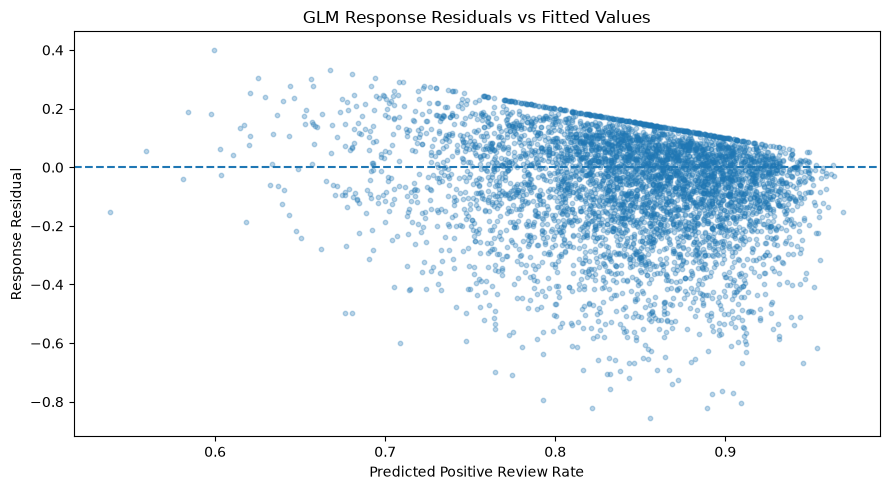

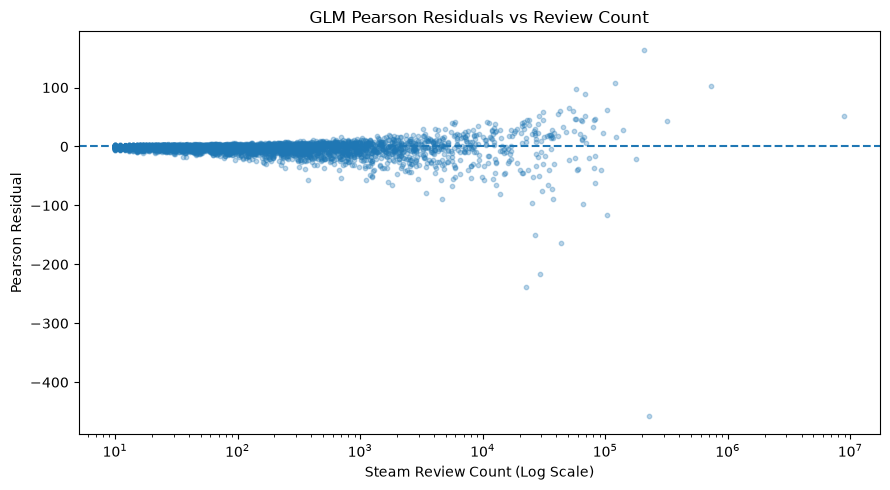

In [12]:

# Step 3: Visualize GLM residuals

import matplotlib.pyplot as plt

# Sample observations for clearer visualization
residual_sample = train_reception.sample(
    n=min(5000, len(train_reception)),
    random_state=config.SEED
)

# Plot 1: Response residuals vs fitted probabilities
plt.figure(figsize=(9, 5))

plt.scatter(
    residual_sample["glm_fitted"],
    residual_sample["response_residual"],
    alpha=0.3,
    s=10
)

plt.axhline(0, linestyle="--")

plt.xlabel("Predicted Positive Review Rate")
plt.ylabel("Response Residual")
plt.title("GLM Response Residuals vs Fitted Values")


plt.tight_layout()
plt.savefig(
    config.FIGURES / "03_q3_glm_response_residuals.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()


# Plot 2: Pearson residuals vs review count
plt.figure(figsize=(9, 5))

plt.scatter(
    residual_sample["steam_review_count"],
    residual_sample["pearson_residual"],
    alpha=0.3,
    s=10
)

plt.axhline(0, linestyle="--")

plt.xscale("log")

plt.xlabel("Steam Review Count (Log Scale)")
plt.ylabel("Pearson Residual")
plt.title("GLM Pearson Residuals vs Review Count")


plt.tight_layout()
plt.savefig(
    config.FIGURES / "03_q3_glm_pearson_residuals.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()


,observed_rate,predicted_rate,games
0,0.7293,0.7281,874
1,0.7458,0.7868,873
2,0.7386,0.8138,873
3,0.7600,0.8327,874
4,0.7670,0.8489,873
5,0.7821,0.8637,873
6,0.7991,0.8778,874
7,0.8028,0.8924,873
8,0.7984,0.9084,873
9,0.8182,0.9318,874


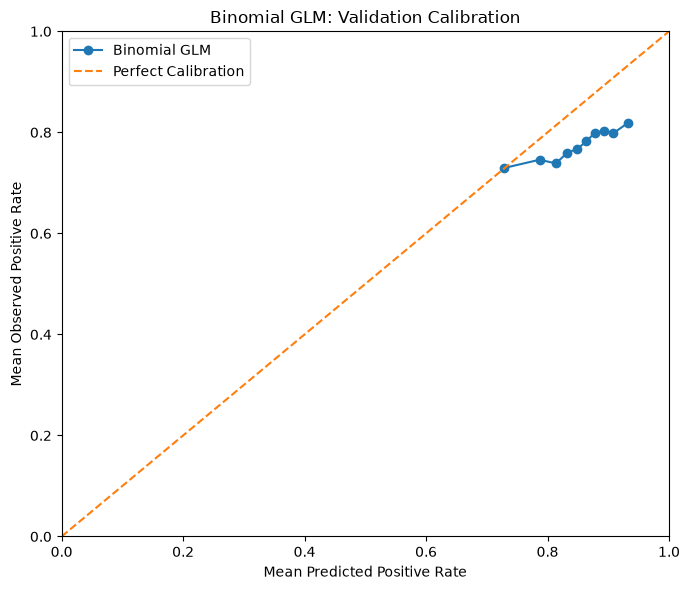

Calibration analysis completed.


In [13]:

# Step 3: Evaluate GLM prediction calibration

# Group validation games into predicted-rate deciles
val_reception["prediction_decile"] = pd.qcut(
    val_reception["glm_prediction"],
    q=10,
    duplicates="drop"
)

# Calculate observed and predicted rates per group
calibration = (
    val_reception
    .groupby("prediction_decile", observed=True)
    .agg(
        observed_rate=("steam_positive_rate", "mean"),
        predicted_rate=("glm_prediction", "mean"),
        games=("steam_appid", "count")
    )
    .reset_index(drop=True)
)

display(calibration.round(4))

# Plot calibration
plt.figure(figsize=(7, 6))

plt.plot(
    calibration["predicted_rate"],
    calibration["observed_rate"],
    marker="o",
    label="Binomial GLM"
)

# Perfect calibration reference
plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Perfect Calibration"
)

plt.xlabel("Mean Predicted Positive Rate")
plt.ylabel("Mean Observed Positive Rate")
plt.title("Binomial GLM: Validation Calibration")

plt.xlim(0, 1)
plt.ylim(0, 1)
plt.legend()


plt.tight_layout()
plt.savefig(
    config.FIGURES / "03_q3_glm_calibration.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()


print("Calibration analysis completed.")


### 1.4 Bayesian Hierarchical Model

A Bayesian hierarchical model will be developed to address limitations identified in the frequentist Binomial GLM, particularly severe overdispersion and unexplained variation in game reception.

A Beta-Binomial likelihood will be considered to accommodate additional variation in positive review probabilities beyond the standard Binomial assumption. Game characteristics will be incorporated as predictors, while developer-level random effects will allow games produced by the same developer to share information through partial pooling.

Prior distributions will be specified for regression coefficients, developer-level variation, and dispersion parameters. The model will be estimated using PyMC, with convergence and posterior predictive checks conducted in subsequent sections.

Before implementation, developer-group frequencies and validation-set coverage will be examined to establish a computationally feasible hierarchical structure and determine how previously unseen developers should be handled.

A preliminary assessment of developer-group frequencies was conducted to determine a computationally feasible hierarchical structure. A minimum threshold of five games per developer was selected, resulting in 987 developer groups covering 9,603 training games (18.89%). Games belonging to developers below this threshold will remain in the analysis but will not receive individual developer random effects. This approach balances computational complexity and developer-level representation, although it limits the proportion of games benefiting directly from hierarchical pooling.

In [5]:

# Step 4: Prepare developer groups for hierarchical modelling

# Count games belonging to each developer
developer_sizes = (
    train_reception["developer_group"].value_counts()
)

# Identify developers with at least two training games
MIN_GAMES_PER_DEVELOPER = 2

repeated_developers = developer_sizes[
    developer_sizes >= MIN_GAMES_PER_DEVELOPER
].index


val_reception["developer_group"] = extract_primary_developer(
    val_reception["steam_developers"],
    val_reception["steam_appid"]
)


# Map repeated training developers to integer indices
developer_mapping = {
    developer: i
    for i, developer in enumerate(repeated_developers)
}

# Assign -1 to single-game or unseen developers
train_reception["developer_hier_idx"] = (
    train_reception["developer_group"]
    .map(developer_mapping)
    .fillna(-1)
    .astype(int)
)

val_reception["developer_hier_idx"] = (
    val_reception["developer_group"]
    .map(developer_mapping)
    .fillna(-1)
    .astype(int)
)

# Summarize hierarchical grouping
developer_summary = pd.DataFrame({
    "Metric": [
        "Training games",
        "Unique training developers",
        "Developers with multiple games",
        "Training games in repeated groups",
        "Training games without repeated groups",
        "Validation games with known repeated developers",
        "Validation games without known repeated developers"
    ],
    "Count": [
        len(train_reception),
        len(developer_sizes),
        len(repeated_developers),
        int((train_reception["developer_hier_idx"] >= 0).sum()),
        int((train_reception["developer_hier_idx"] == -1).sum()),
        int((val_reception["developer_hier_idx"] >= 0).sum()),
        int((val_reception["developer_hier_idx"] == -1).sum())
    ]
})

display(developer_summary)

# Validation checks
assert len(developer_mapping) == len(repeated_developers)

assert (
    train_reception["developer_hier_idx"].ge(-1)
).all()

assert (
    val_reception["developer_hier_idx"].ge(-1)
).all()

assert (
    developer_summary.loc[3, "Count"]
    + developer_summary.loc[4, "Count"]
    == len(train_reception)
)

assert (
    developer_summary.loc[5, "Count"]
    + developer_summary.loc[6, "Count"]
    == len(val_reception)
)

print("\nHierarchical developer grouping checks passed.")


,Metric,Count
0,Training games,34935
1,Unique training developers,22657
2,Developers with multiple games,5065
3,Training games in repeated groups,17343
4,Training games without repeated groups,17592
5,Validation games with known repeated developers,2899
6,Validation games without known repeated develo...,5835



Hierarchical developer grouping checks passed.


In [15]:

# Step 4: Evaluate developer-grouping thresholds

DEVELOPER_THRESHOLDS = [2, 3, 5, 10, 20]

threshold_results = []

for threshold in DEVELOPER_THRESHOLDS:

    # Developers meeting the minimum game count
    eligible_developers = developer_sizes[
        developer_sizes >= threshold
    ].index

    # Identify games belonging to these developers
    train_mask = train_reception[
        "developer_group"
    ].isin(eligible_developers)

    val_mask = val_reception[
        "developer_group"
    ].isin(eligible_developers)

    threshold_results.append({
        "Minimum Games": threshold,
        "Developer Groups": len(eligible_developers),
        "Training Games Covered": int(train_mask.sum()),
        "Training Coverage (%)": round(
            train_mask.mean() * 100, 2
        ),
        "Validation Games Covered": int(val_mask.sum()),
        "Validation Coverage (%)": round(
            val_mask.mean() * 100, 2
        )
    })

threshold_summary = pd.DataFrame(threshold_results)

display(threshold_summary)

print("\nDeveloper group size distribution:")

display(
    developer_sizes.describe(
        percentiles=[0.50, 0.75, 0.90, 0.95, 0.99]
    ).round(2)
)

# Validation checks
assert threshold_summary[
    "Developer Groups"
].is_monotonic_decreasing

assert threshold_summary[
    "Training Games Covered"
].is_monotonic_decreasing

assert threshold_summary[
    "Validation Games Covered"
].is_monotonic_decreasing

print("\nDeveloper threshold checks passed.")


,Minimum Games,Developer Groups,Training Games Covered,Training Coverage (%),Validation Games Covered,Validation Coverage (%)
0,2,5065,17343,49.64,2899,33.19
1,3,2151,11515,32.96,2171,24.86
2,5,745,6862,19.64,1442,16.51
3,10,185,3415,9.78,778,8.91
4,20,49,1674,4.79,408,4.67



Developer group size distribution:


count    22657.00
mean         1.54
std          2.18
min          1.00
50%          1.00
75%          1.00
90%          2.00
95%          4.00
99%          9.00
max         93.00
Name: count, dtype: float64


Developer threshold checks passed.


In [6]:

# Step 4: Select Bayesian MCMC training subset

MIN_REVIEWS_BAYES = 50

train_bayes = train_reception.loc[
    train_reception["steam_review_count"] >= MIN_REVIEWS_BAYES
].copy()

# Developer frequencies within the Bayesian subset
bayes_developer_sizes = (
    train_bayes["developer_group"].value_counts()
)

print("Bayesian training games:", len(train_bayes))
print("Unique developers:", len(bayes_developer_sizes))
print(
    "Developers with at least 5 games:",
    int((bayes_developer_sizes >= 5).sum())
)

# Validation
assert len(train_bayes) > 0
assert train_bayes["steam_review_count"].ge(50).all()
assert train_bayes.index.isin(train_reception.index).all()

print("\nBayesian training subset checks passed.")


Bayesian training games: 18981
Unique developers: 12381
Developers with at least 5 games: 398

Bayesian training subset checks passed.


In [7]:

# Step 4: Prepare Bayesian hierarchical model inputs

MIN_GAMES_HIERARCHICAL = 5

# Identify developers with at least 5 training games
hierarchical_developers = bayes_developer_sizes[
    bayes_developer_sizes >= MIN_GAMES_HIERARCHICAL
].index


# Create integer mapping for developer groups
developer_mapping = {
    developer: idx
    for idx, developer in enumerate(hierarchical_developers)
}

N_DEVELOPERS = len(developer_mapping)

# Prepare safe developer indices
for dataset in [train_bayes, val_reception]:

    mapped = dataset["developer_group"].map(
        developer_mapping
    )

    # Indicate whether developer has a random effect
    dataset["has_developer_effect"] = (
        mapped.notna().astype(int)
    )

    # Use a safe index for PyMC arrays
    # The indicator will mask games without developer effects
    dataset["developer_idx_safe"] = (
        mapped.fillna(0).astype(int)
    )

# Identify continuous predictors
CONTINUOUS_FEATURES = [
    "feature_log_price",
    "steam_years_since_release",
    "feature_log_language_count_imputed"
]

# Calculate scaling parameters using training data only
feature_means = train_bayes[
    CONTINUOUS_FEATURES
].mean()

feature_stds = train_bayes[
    CONTINUOUS_FEATURES
].std()

assert feature_stds.gt(0).all()

# Create predictor matrices
X_train_bayes = train_bayes[
    MODEL_FEATURES
].astype(float).copy()

X_val_bayes = val_reception[
    MODEL_FEATURES
].astype(float).copy()

# Standardize continuous features
for col in CONTINUOUS_FEATURES:

    X_train_bayes[col] = (
        X_train_bayes[col] - feature_means[col]
    ) / feature_stds[col]

    X_val_bayes[col] = (
        X_val_bayes[col] - feature_means[col]
    ) / feature_stds[col]

# Prepare observed review counts
y_positive_bayes = train_bayes[
    "steam_positive"
].to_numpy(dtype="int64")

n_reviews_bayes = train_bayes[
    "steam_review_count"
].to_numpy(dtype="int64")

# Prepare safe developer indices and indicators
dev_idx_train = train_bayes[
    "developer_idx_safe"
].to_numpy(dtype="int32")

dev_mask_train = train_bayes[
    "has_developer_effect"
].to_numpy(dtype="float64")

dev_idx_val = val_reception[
    "developer_idx_safe"
].to_numpy(dtype="int32")

dev_mask_val = val_reception[
    "has_developer_effect"
].to_numpy(dtype="float64")

print("Bayesian model inputs prepared.\n")

print("Training observations:", len(X_train_bayes))
print("Validation observations:", len(X_val_bayes))
print("Predictors:", X_train_bayes.shape[1])
print("Developer groups:", N_DEVELOPERS)

print("\nTraining games with developer effects:",
      int(dev_mask_train.sum()))

print("Validation games with developer effects:",
      int(dev_mask_val.sum()))

# Validation checks
assert X_train_bayes.shape == (
    len(train_bayes), len(MODEL_FEATURES)
)

assert X_val_bayes.shape == (
    len(val_reception), len(MODEL_FEATURES)
)

assert (y_positive_bayes <= n_reviews_bayes).all()
assert (y_positive_bayes >= 0).all()
assert (n_reviews_bayes > 0).all()

assert np.isfinite(X_train_bayes.to_numpy()).all()
assert np.isfinite(X_val_bayes.to_numpy()).all()

assert dev_idx_train.min() >= 0
assert dev_idx_train.max() < N_DEVELOPERS

assert dev_idx_val.min() >= 0
assert dev_idx_val.max() < N_DEVELOPERS

print("\nBayesian input validation checks passed.")


Bayesian model inputs prepared.

Training observations: 18981
Validation observations: 8734
Predictors: 35
Developer groups: 398

Training games with developer effects: 3441
Validation games with developer effects: 892

Bayesian input validation checks passed.


In [ ]:

# Verify Bayesian modelling packages

import sys
import pymc as pm
import arviz as az

print("Python:", sys.version.split()[0])
print("PyMC version:", pm.__version__)
print("ArviZ version:", az.__version__)

print("\nBayesian libraries imported successfully.")


g++ not available, if using conda: `conda install gxx`


Python: 3.14.7
PyMC version: 6.3.2
ArviZ version: 1.3.0

Bayesian libraries imported successfully.


In [8]:

# Step 4: Define Bayesian hierarchical Beta-Binomial model

import pymc as pm

print("PyMC version:", pm.__version__)


# Exclude predictors that are constant in the Bayesian training subset
BAYES_FEATURES = [
    feature for feature in MODEL_FEATURES
    if X_train_bayes[feature].nunique(dropna=False) > 1
]

print("Bayesian predictors:", len(BAYES_FEATURES))
print(
    "Excluded constant predictors:",
    [f for f in MODEL_FEATURES if f not in BAYES_FEATURES]
)


# Define model coordinates
coords = {
    "feature": BAYES_FEATURES,
    "developer": np.arange(N_DEVELOPERS),
    "game": np.arange(len(X_train_bayes))
}


with pm.Model(coords=coords) as bayes_model:

    # Model input data

    X_data = pm.Data(
        "X_data",
        X_train_bayes[BAYES_FEATURES].to_numpy(dtype="float64"),
        dims=("game", "feature")
    )


    developer_idx = pm.Data(
        "developer_idx",
        dev_idx_train,
        dims="game"
    )

    developer_mask = pm.Data(
        "developer_mask",
        dev_mask_train,
        dims="game"
    )

    review_totals = pm.Data(
        "review_totals",
        n_reviews_bayes,
        dims="game"
    )

    # Prior for the intercept
    intercept = pm.Normal(
        "intercept",
        mu=0,
        sigma=2
    )

    # Priors for regression coefficients
    beta = pm.Normal(
        "beta",
        mu=0,
        sigma=0.5,
        dims="feature"
    )

    # Developer-level variation
    sigma_developer = pm.HalfNormal(
        "sigma_developer",
        sigma=0.5
    )

    # Non-centered developer effects
    developer_z = pm.Normal(
        "developer_z",
        mu=0,
        sigma=1,
        dims="developer"
    )

    developer_effect = sigma_developer * developer_z

    # Apply developer effects only to eligible groups
    developer_adjustment = (
        developer_effect[developer_idx]
        * developer_mask
    )

    # Linear predictor
    eta = (
        intercept
        + pm.math.dot(X_data, beta)
        + developer_adjustment
    )

    # Expected positive review probability
    mu = pm.math.sigmoid(eta)

    # Beta-Binomial concentration parameter
    concentration = pm.LogNormal(
        "concentration",
        mu=np.log(20),
        sigma=1
    )

    # Beta distribution parameters
    alpha = mu * concentration
    beta_param = (1 - mu) * concentration

    # Beta-Binomial likelihood
    reviews = pm.BetaBinomial(
        "reviews",
        alpha=alpha,
        beta=beta_param,
        n=review_totals,
        observed=y_positive_bayes,
        dims="game"
    )

print("\nBayesian hierarchical model defined successfully.")

print("Free model parameters:")
for variable in bayes_model.free_RVs:
    print("-", variable.name)

print("\nObserved variables:")
for variable in bayes_model.observed_RVs:
    print("-", variable.name)


PyMC version: 6.3.2
Bayesian predictors: 34
Excluded constant predictors: ['flag_missing_tags']

Bayesian hierarchical model defined successfully.
Free model parameters:
- intercept
- beta
- sigma_developer
- developer_z
- concentration

Observed variables:
- reviews


In [9]:

# Step 4: Verify Bayesian model specification

print("Checking Bayesian model structure...\n")

# Validate model dimensions
assert len(bayes_model.coords["feature"]) == len(BAYES_FEATURES)
assert N_DEVELOPERS == len(developer_mapping)


assert len(y_positive_bayes) == len(n_reviews_bayes)
assert len(y_positive_bayes) == len(X_train_bayes)

# Check that observed counts are valid
assert (y_positive_bayes >= 0).all()
assert (y_positive_bayes <= n_reviews_bayes).all()
assert (n_reviews_bayes > 0).all()

# Check developer indices and masks
assert np.isin(dev_mask_train, [0, 1]).all()
assert dev_idx_train.min() >= 0
assert dev_idx_train.max() < N_DEVELOPERS

# Draw a small sample from the prior model
# This does not fit the model or run MCMC sampling
with bayes_model:
    prior_mu = pm.draw(
        mu[:10],
        draws=1,
        random_seed=config.SEED
    )

print("Example prior positive review probabilities:")
print(np.round(prior_mu, 4))

# Verify probabilities
assert np.isfinite(prior_mu).all()
assert np.all((prior_mu >= 0) & (prior_mu <= 1))

print("\nModel dimensions:")
print("Training observations:", len(y_positive_bayes))
print("Predictors:", len(BAYES_FEATURES))
print("Developer effects:", N_DEVELOPERS)

print("\nBayesian model specification checks passed.")


Checking Bayesian model structure...

Example prior positive review probabilities:
[0.6894 0.6942 0.85   0.9743 0.7403 0.396  0.9645 0.2709 0.9188 0.9683]

Model dimensions:
Training observations: 18981
Predictors: 34
Developer effects: 398

Bayesian model specification checks passed.


In [ ]:

# Step 4: Create a smaller Bayesian pilot model

# Select 10 developers with at least 5 games
pilot_developers = developer_sizes[
    developer_sizes >= 5
].head(10).index.tolist()

# Sample 5 games from each selected developer
pilot_grouped = (
    train_reception[
        train_reception["developer_group"].isin(pilot_developers)
    ]
    .groupby("developer_group")
    .sample(n=5, random_state=config.SEED)
)

# Sample 250 games without explicit developer effects
pilot_ungrouped = train_reception[
    train_reception["has_developer_effect"] == 0
].sample(n=250, random_state=config.SEED)

# Combine and shuffle
pilot_df = pd.concat([
    pilot_grouped,
    pilot_ungrouped
]).sample(frac=1, random_state=config.SEED)

# Reuse previously standardized predictors
X_pilot = X_train_bayes.loc[
    pilot_df.index, MODEL_FEATURES
].to_numpy(dtype="float64")

# Prepare observed review counts
y_pilot = pilot_df[
    "steam_positive"
].to_numpy(dtype="int64")

n_pilot = pilot_df[
    "steam_review_count"
].to_numpy(dtype="int64")

# Remap developer indices for the smaller model
pilot_mapping = {
    developer: i
    for i, developer in enumerate(pilot_developers)
}

pilot_dev_idx = (
    pilot_df["developer_group"]
    .map(pilot_mapping)
    .fillna(0)
    .to_numpy(dtype="int32")
)

pilot_dev_mask = (
    pilot_df["developer_group"]
    .isin(pilot_developers)
    .to_numpy(dtype="float64")
)

# Define pilot Bayesian model
with pm.Model() as pilot_model:

    intercept = pm.Normal(
        "intercept", mu=0, sigma=2
    )

    beta = pm.Normal(
        "beta", mu=0, sigma=0.5,
        shape=len(MODEL_FEATURES)
    )

    sigma_developer = pm.HalfNormal(
        "sigma_developer", sigma=0.5
    )

    developer_z = pm.Normal(
        "developer_z",
        mu=0, sigma=1,
        shape=len(pilot_developers)
    )

    developer_effect = (
        sigma_developer * developer_z
    )

    eta = (
        intercept
        + pm.math.dot(X_pilot, beta)
        + developer_effect[pilot_dev_idx] * pilot_dev_mask
    )

    mu = pm.math.sigmoid(eta)

    concentration = pm.LogNormal(
        "concentration",
        mu=np.log(20),
        sigma=1
    )

    pm.BetaBinomial(
        "reviews",
        alpha=mu * concentration,
        beta=(1 - mu) * concentration,
        n=n_pilot,
        observed=y_pilot
    )

# Validate pilot dimensions
assert len(pilot_df) == 300
assert X_pilot.shape == (300, 12)
assert len(pilot_developers) == 10
assert (y_pilot <= n_pilot).all()

print("Pilot Bayesian model created successfully.")
print("Pilot games:", len(pilot_df))
print("Predictors:", X_pilot.shape[1])
print("Developer effects:", len(pilot_developers))
print("\nPilot model checks passed.")


Pilot Bayesian model created successfully.
Pilot games: 300
Predictors: 12
Developer effects: 10

Pilot model checks passed.


In [ ]:

# Step 4: Test posterior sampling on the smaller model

print("Starting reduced Bayesian pilot sampling...")

with pilot_model:

    pilot_trace = pm.sample(
        draws=20,
        tune=20,
        chains=1,
        cores=1,
        random_seed=config.SEED,
        nuts_sampler="pymc",
        nuts={"target_accept": 0.90},
        progressbar=True,
        compute_convergence_checks=False,
        idata_kwargs={"log_likelihood": False}
    )

print("\nPilot sampling completed.")

# Verify returned samples
posterior = pilot_trace.posterior

print("Posterior draws:", posterior.sizes["draw"])
print("Chains:", posterior.sizes["chain"])

divergences = int(
    pilot_trace.sample_stats["diverging"].sum().item()
)

print("Divergent transitions:", divergences)

assert posterior.sizes["draw"] == 20
assert posterior.sizes["chain"] == 1

print("\nPilot sampling checks passed.")


Only 20 samples per chain. Reliable r-hat and ESS diagnostics require longer chains for accurate estimate.


Starting reduced Bayesian pilot sampling...


Initializing NUTS using jitter+adapt_diag...
Sequential sampling (1 chains in 1 job)
NUTS: [intercept, beta, sigma_developer, developer_z, concentration]


c:\Users\sheen\AppData\Local\Programs\Python\Python314\Lib\site-packages\rich\live.py:260: UserWarning: install 
"ipywidgets" for Jupyter support
  warnings.warn('install "ipywidgets" for Jupyter support')

c:\Users\sheen\AppData\Local\Programs\Python\Python314\Lib\site-packages\pymc\sampling\mcmc.py:1178: FutureWarning: Passing `log_likelihood` via `idata_kwargs` is deprecated and will be removed in future versions. Call `pm.compute_log_likelihood(idata)` instead.
  return _sample_return(
Sampling 1 chain for 20 tune and 20 draw iterations (20 + 20 draws total) took 1 seconds.



Pilot sampling completed.
Posterior draws: 20
Chains: 1
Divergent transitions: 0

Pilot sampling checks passed.


In [ ]:

# Step 4: Test ADVI on the full Bayesian model

import time

ADVI_TEST_ITERATIONS = 100

print("Starting full-data ADVI feasibility test...")
print("Training observations:", len(X_train_bayes))
print("Developer effects:", N_DEVELOPERS)

start = time.perf_counter()

with bayes_model:
    advi_test = pm.fit(
        n=ADVI_TEST_ITERATIONS,
        method="advi",
        random_seed=config.SEED,
        progressbar=False
    )

elapsed = time.perf_counter() - start

# Inspect optimization loss
advi_losses = np.asarray(advi_test.hist)

print("\nADVI test completed.")
print("Iterations:", len(advi_losses))
print("Elapsed seconds:", round(elapsed, 2))
print("Initial loss:", round(float(advi_losses[0]), 2))
print("Final loss:", round(float(advi_losses[-1]), 2))

# Validate optimization output
assert len(advi_losses) == ADVI_TEST_ITERATIONS
assert np.isfinite(advi_losses).all()

print("\nADVI feasibility checks passed.")
print("Note: This short test is not a fitted final model.")


Starting full-data ADVI feasibility test...
Training observations: 50843
Developer effects: 987


Finished [100%]: Average Loss = 6.2161e+05



ADVI test completed.
Iterations: 100
Elapsed seconds: 4.22
Initial loss: 673688.03
Final loss: 1030540.97

ADVI feasibility checks passed.
Note: This short test is not a fitted final model.


In [10]:

# Step 4: Fit Bayesian hierarchical Beta-Binomial using MCMC

print("Starting Bayesian MCMC sampling...")
print("Training observations:", len(X_train_bayes))
print("Predictors:", len(BAYES_FEATURES))
print("Developer effects:", N_DEVELOPERS)

with bayes_model:
    bayes_trace = pm.sample(
        draws=1000,
        tune=1000,
        chains=2,
        cores=1,
        random_seed=config.SEED,
        target_accept=0.90,
        progressbar=True,
        return_inferencedata=True,
        idata_kwargs={"log_likelihood": False}
    )

print("\nBayesian MCMC sampling completed.")

# Verify posterior dimensions
posterior = bayes_trace.posterior

print("Posterior draws per chain:", posterior.sizes["draw"])
print("Chains:", posterior.sizes["chain"])

# Count divergent transitions
divergences = int(
    bayes_trace.sample_stats["diverging"].sum().item()
)

print("Divergent transitions:", divergences)

assert posterior.sizes["draw"] == 1000
assert posterior.sizes["chain"] == 2

print("\nMCMC sampling checks passed.")


Starting Bayesian MCMC sampling...
Training observations: 18981
Predictors: 34
Developer effects: 398


Initializing NUTS using jitter+adapt_diag...
Sequential sampling (2 chains in 1 job)
NUTS: [intercept, beta, sigma_developer, developer_z, concentration]


Output()

c:\Users\sheen\AppData\Local\Programs\Python\Python314\Lib\site-packages\pymc\sampling\mcmc.py:1178: FutureWarning: Passing `log_likelihood` via `idata_kwargs` is deprecated and will be removed in future versions. Call `pm.compute_log_likelihood(idata)` instead.
  return _sample_return(
Sampling 2 chains for 1_000 tune and 1_000 draw iterations (2_000 + 2_000 draws total) took 3775 seconds.
We recommend running at least 4 chains for robust computation of convergence diagnostics
The rhat statistic is larger than 1.01 for some parameters. This indicates problems during sampling. See https://arxiv.org/abs/1903.08008 for details



Bayesian MCMC sampling completed.
Posterior draws per chain: 1000
Chains: 2
Divergent transitions: 0

MCMC sampling checks passed.


In [12]:

# Step 4: Save Bayesian MCMC posterior samples

import arviz as az

config.TABLES.mkdir(parents=True, exist_ok=True)

trace_path = (
    config.TABLES / "03_q4_bayesian_mcmc_trace.nc"
)


bayes_trace.to_netcdf(str(trace_path))


assert trace_path.exists()

print("Bayesian MCMC trace saved successfully.")
print("Path:", trace_path)
print("Posterior chains:", bayes_trace.posterior.sizes["chain"])
print("Draws per chain:", bayes_trace.posterior.sizes["draw"])


ValueError: cannot write NetCDF files with format='NETCDF4' because none of the suitable backend libraries (netCDF4, h5netcdf) are installed

Continuing ADVI optimization...


Finished [100%]: Average Loss = 4.1828e+05



ADVI Optimization Summary:
Total iterations: 1000
Previous 100 mean loss: 437903.28
Latest 100 mean loss: 359940.32
Relative change (%): -17.8


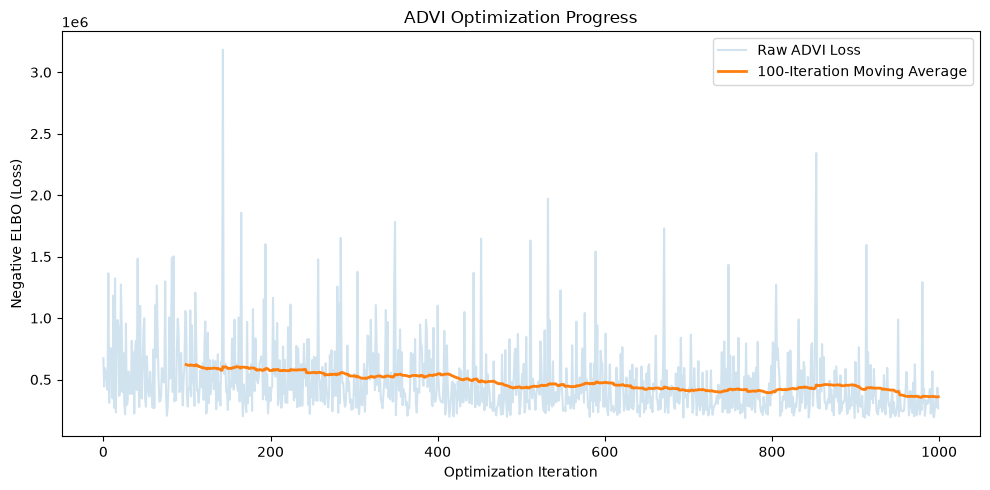


ADVI refinement checks passed.


In [ ]:

# Step 4: Continue ADVI optimization

ADDITIONAL_ITERATIONS = 500

print("Continuing ADVI optimization...")

# Continue from the existing optimization state
with bayes_model:
    advi_inference.refine(
        n=ADDITIONAL_ITERATIONS,
        progressbar=True
    )

# Retrieve the complete optimization history
advi_history = np.asarray(advi_inference.hist)

# Compare recent optimization performance
previous_mean = np.mean(advi_history[400:500])
current_mean = np.mean(advi_history[-100:])

relative_change = (
    (current_mean - previous_mean)
    / abs(previous_mean) * 100
)

print("\nADVI Optimization Summary:")
print("Total iterations:", len(advi_history))
print("Previous 100 mean loss:", round(previous_mean, 2))
print("Latest 100 mean loss:", round(current_mean, 2))
print("Relative change (%):", round(relative_change, 2))

# Plot complete optimization history
rolling_loss = pd.Series(
    advi_history
).rolling(window=100).mean()

plt.figure(figsize=(10, 5))

plt.plot(
    advi_history,
    alpha=0.2,
    label="Raw ADVI Loss"
)

plt.plot(
    rolling_loss,
    linewidth=2,
    label="100-Iteration Moving Average"
)

plt.xlabel("Optimization Iteration")
plt.ylabel("Negative ELBO (Loss)")
plt.title("ADVI Optimization Progress")


plt.legend()
plt.tight_layout()
plt.savefig(
    config.FIGURES / "03_q4_advi_refinement.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()


# Validation
assert len(advi_history) == 1000
assert np.isfinite(advi_history).all()

print("\nADVI refinement checks passed.")


Continuing ADVI optimization...


Finished [100%]: Average Loss = 2.5105e+05



ADVI Optimization Summary:
Total iterations: 3000
Previous 200 mean loss: 242958.61
Latest 200 mean loss: 235848.19
Relative change (%): -2.93


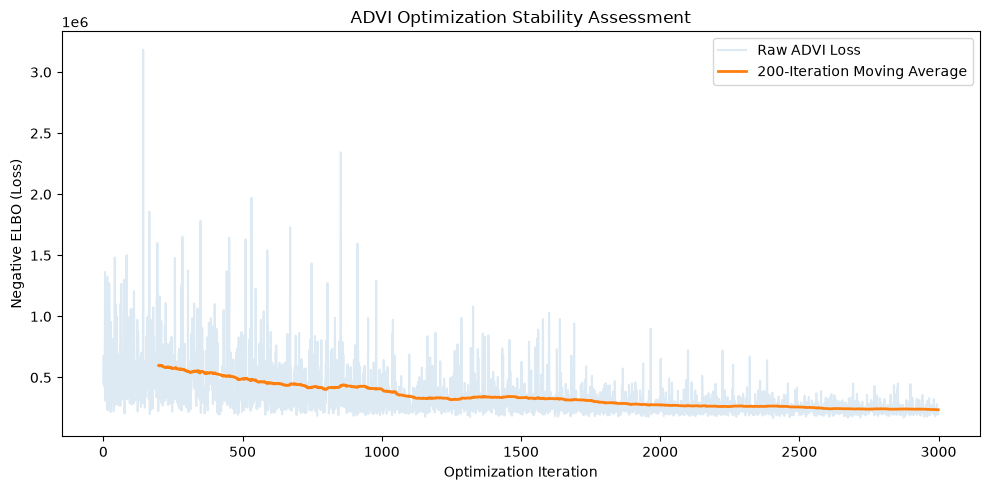


ADVI stability assessment completed.
Recent average losses appear relatively stable.
Posterior accuracy is not yet established.


In [ ]:

# Step 4: Continue ADVI optimization and assess stability

ADDITIONAL_ITERATIONS = 2000

print("Continuing ADVI optimization...")

# Continue from existing optimization state
with bayes_model:
    advi_inference.refine(
        n=ADDITIONAL_ITERATIONS,
        progressbar=True
    )

# Retrieve complete optimization history
advi_history = np.asarray(advi_inference.hist)

# Compare two recent non-overlapping windows
previous_mean = np.mean(advi_history[-400:-200])
latest_mean = np.mean(advi_history[-200:])

relative_change = (
    (latest_mean - previous_mean)
    / abs(previous_mean) * 100
)

print("\nADVI Optimization Summary:")
print("Total iterations:", len(advi_history))
print("Previous 200 mean loss:", round(previous_mean, 2))
print("Latest 200 mean loss:", round(latest_mean, 2))
print("Relative change (%):", round(relative_change, 2))

# Plot optimization progress
rolling_loss = pd.Series(advi_history).rolling(
    window=200
).mean()

plt.figure(figsize=(10, 5))

plt.plot(
    advi_history,
    alpha=0.15,
    label="Raw ADVI Loss"
)

plt.plot(
    rolling_loss,
    linewidth=2,
    label="200-Iteration Moving Average"
)

plt.xlabel("Optimization Iteration")
plt.ylabel("Negative ELBO (Loss)")
plt.title("ADVI Optimization Stability Assessment")

plt.legend()
plt.tight_layout()
plt.savefig(
    config.FIGURES / "03_q4_advi_stability.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()



# Validation checks
assert len(advi_history) == 3000
assert np.isfinite(advi_history).all()

print("\nADVI stability assessment completed.")

if abs(relative_change) < 3:
    print("Recent average losses appear relatively stable.")
else:
    print("Recent average losses are still changing.")

print("Posterior accuracy is not yet established.")


### 1.5 Bayesian Model Diagnostics
 
Bayesian model diagnostics are conducted to assess the stability and suitability of the hierarchical Beta-Binomial model estimated using Automatic Differentiation Variational Inference (ADVI).

The optimization process completed 3,000 iterations, with the negative ELBO showing an overall decreasing trend. The relative change between the final two 200-iteration windows was -2.93%, suggesting that optimization was becoming more stable.

Approximate posterior samples will be generated to examine regression coefficients, developer-level variability, and the Beta-Binomial concentration parameter. Posterior predictive checks will subsequently assess whether the fitted model can reproduce key characteristics of the observed review data.

Since ADVI produces an approximate posterior rather than MCMC chains, traditional R-hat and effective sample size diagnostics are not applicable. Model assessment will therefore focus on optimization stability, posterior distributions, predictive checks, and sensitivity analysis.

In [ ]:

# Step 5: Generate approximate posterior samples

POSTERIOR_DRAWS = 300

print("Generating approximate posterior samples...")

# Sample from the existing ADVI approximation
with bayes_model:
    advi_trace = advi_inference.approx.sample(
        draws=POSTERIOR_DRAWS,
        random_seed=config.SEED,
        return_inferencedata=True
    )

posterior = advi_trace.posterior

print("\nPosterior sampling completed.")
print("Draws:", posterior.sizes["draw"])
print("Chains:", posterior.sizes["chain"])

# Convert posterior variables to NumPy arrays
def get_posterior_draws(name):
    values = np.asarray(posterior[name].values)
    return values.reshape((-1,) + values.shape[2:])

# Summarize posterior distributions
summary_rows = []

for name in [
    "intercept",
    "sigma_developer",
    "concentration"
]:
    values = get_posterior_draws(name)

    summary_rows.append({
        "Parameter": name,
        "Mean": np.mean(values),
        "SD": np.std(values),
        "5%": np.quantile(values, 0.05),
        "95%": np.quantile(values, 0.95)
    })

# Summarize regression coefficients
beta_draws = get_posterior_draws("beta")

for i, feature in enumerate(MODEL_FEATURES):

    values = beta_draws[:, i]

    summary_rows.append({
        "Parameter": feature,
        "Mean": np.mean(values),
        "SD": np.std(values),
        "5%": np.quantile(values, 0.05),
        "95%": np.quantile(values, 0.95)
    })

posterior_summary = pd.DataFrame(summary_rows)

print("\nApproximate posterior summary:")
display(posterior_summary.round(4))

# Validation checks
assert posterior.sizes["draw"] == POSTERIOR_DRAWS

assert beta_draws.shape == (
    POSTERIOR_DRAWS,
    len(MODEL_FEATURES)
)

assert np.isfinite(
    posterior_summary[["Mean", "SD", "5%", "95%"]]
    .to_numpy()
).all()

assert (
    get_posterior_draws("concentration") > 0
).all()

assert (
    get_posterior_draws("sigma_developer") > 0
).all()

print("\nApproximate posterior checks passed.")


Generating approximate posterior samples...

Posterior sampling completed.
Draws: 300
Chains: 1

Approximate posterior summary:


,Parameter,Mean,SD,5%,95%
0,intercept,0.5722,0.5191,-0.2969,1.3972
1,sigma_developer,0.4858,0.2842,0.1873,0.9962
2,concentration,17.4149,11.5879,5.8315,37.1558
3,genre_indie,0.4893,0.4889,-0.3490,1.3181
4,genre_casual,0.4519,0.5289,-0.4891,1.2561
5,genre_action,0.4205,0.4892,-0.3527,1.2288
6,genre_adventure,0.4830,0.5236,-0.4111,1.3340
7,genre_simulation,0.3333,0.5549,-0.6112,1.2246
8,genre_strategy,0.4035,0.5225,-0.3842,1.2746
9,genre_rpg,0.3753,0.5432,-0.5862,1.1995



Approximate posterior checks passed.


In [ ]:

# Step 5: Bayesian posterior predictive checks

from scipy.special import expit

rng = np.random.default_rng(config.SEED)

PPC_GAMES = 1000
PPC_DRAWS = 200

# Select reproducible training observations
sample_idx = np.sort(
    rng.choice(
        len(train_reception),
        size=PPC_GAMES,
        replace=False
    )
)

# Prepare predictors and review counts
X_ppc = X_train_bayes.iloc[
    sample_idx
].to_numpy(dtype=float)

n_ppc = n_reviews_bayes[sample_idx]
y_ppc = y_positive_bayes[sample_idx]

dev_idx_ppc = dev_idx_train[sample_idx]
dev_mask_ppc = dev_mask_train[sample_idx]

# Select posterior draws
draw_idx = np.linspace(
    0,
    POSTERIOR_DRAWS - 1,
    PPC_DRAWS,
    dtype=int
)

intercept_ppc = get_posterior_draws(
    "intercept"
)[draw_idx, None]

beta_ppc = get_posterior_draws(
    "beta"
)[draw_idx]

sigma_ppc = get_posterior_draws(
    "sigma_developer"
)[draw_idx, None]

developer_z_ppc = get_posterior_draws(
    "developer_z"
)[draw_idx]

concentration_ppc = get_posterior_draws(
    "concentration"
)[draw_idx, None]

# Calculate the linear predictor
developer_adjustment = (
    sigma_ppc
    * developer_z_ppc[:, dev_idx_ppc]
    * dev_mask_ppc[None, :]
)

eta_ppc = (
    intercept_ppc
    + beta_ppc @ X_ppc.T
    + developer_adjustment
)

# Expected positive review probabilities
mu_ppc = expit(eta_ppc)

# Generate replicated Beta-Binomial outcomes
alpha_ppc = np.maximum(
    mu_ppc * concentration_ppc,
    1e-8
)

beta_param_ppc = np.maximum(
    (1 - mu_ppc) * concentration_ppc,
    1e-8
)

review_probabilities = rng.beta(
    alpha_ppc,
    beta_param_ppc
)

replicated_positive = rng.binomial(
    n_ppc[None, :],
    review_probabilities
)

# Convert replicated counts into review rates
replicated_rates = (
    replicated_positive / n_ppc[None, :]
)

observed_rates = y_ppc / n_ppc

# Compare observed and replicated statistics
statistics = [
    (
        "Mean positive rate",
        observed_rates.mean(),
        replicated_rates.mean(axis=1)
    ),
    (
        "SD of positive rate",
        observed_rates.std(ddof=1),
        replicated_rates.std(axis=1, ddof=1)
    ),
    (
        "Fraction with >=90% positive",
        np.mean(observed_rates >= 0.9),
        np.mean(replicated_rates >= 0.9, axis=1)
    ),
    (
        "Fraction with <=50% positive",
        np.mean(observed_rates <= 0.5),
        np.mean(replicated_rates <= 0.5, axis=1)
    )
]

ppc_summary = pd.DataFrame([
    {
        "Statistic": name,
        "Observed": observed,
        "Predicted Mean": simulated.mean(),
        "Predicted 5%": np.quantile(simulated, 0.05),
        "Predicted 95%": np.quantile(simulated, 0.95)
    }
    for name, observed, simulated in statistics
])

display(ppc_summary.round(4))

# Validation
assert replicated_rates.shape == (
    PPC_DRAWS, PPC_GAMES
)

assert np.isfinite(replicated_rates).all()
assert (
    (replicated_rates >= 0)
    & (replicated_rates <= 1)
).all()

print("\nPosterior predictive checks completed.")


,Statistic,Observed,Predicted Mean,Predicted 5%,Predicted 95%
0,Mean positive rate,0.7549,0.7845,0.5849,0.9181
1,SD of positive rate,0.2345,0.2262,0.1450,0.3056
2,Fraction with >=90% positive,0.3160,0.4615,0.1869,0.7334
3,Fraction with <=50% positive,0.1440,0.1575,0.0300,0.3972



Posterior predictive checks completed.


Bayesian validation calibration:


,observed_rate,predicted_rate,games
0,0.7286,0.6631,1272
1,0.7417,0.7145,1271
2,0.7467,0.7437,1271
3,0.7740,0.7628,1271
4,0.7583,0.7826,1271
5,0.7581,0.8003,1271
6,0.7754,0.8159,1271
7,0.7650,0.8336,1271
8,0.7709,0.8543,1271
9,0.7509,0.8872,1271


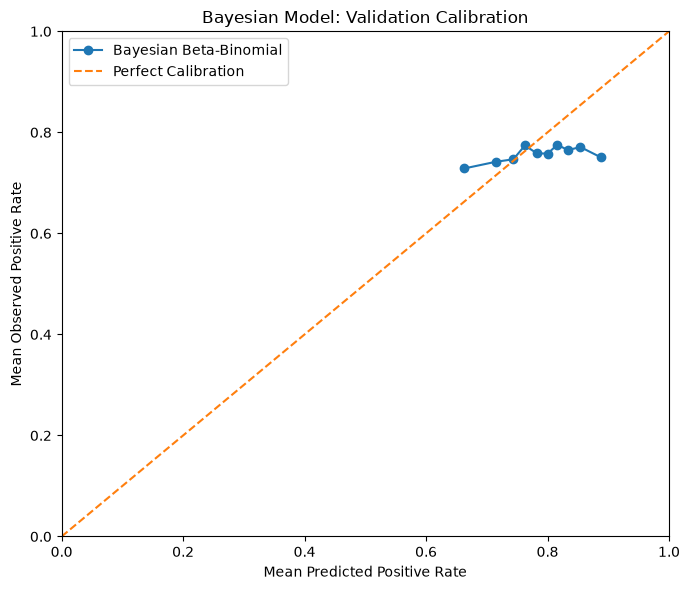


Bayesian validation calibration checks passed.


In [ ]:

# Step 5: Bayesian validation predictions and calibration

from scipy.special import expit
import matplotlib.pyplot as plt

# Use 200 draws from the approximate posterior
N_PRED_DRAWS = 200

draw_idx = np.linspace(
    0, POSTERIOR_DRAWS - 1,
    N_PRED_DRAWS,
    dtype=int
)

# Extract posterior parameters
intercept_val = get_posterior_draws(
    "intercept"
)[draw_idx, None]

beta_val = get_posterior_draws(
    "beta"
)[draw_idx]

sigma_val = get_posterior_draws(
    "sigma_developer"
)[draw_idx, None]

developer_z_val = get_posterior_draws(
    "developer_z"
)[draw_idx]

# Prepare validation predictors
X_validation = X_val_bayes[
    MODEL_FEATURES
].to_numpy(dtype=float)

# Calculate developer adjustments
developer_adjustment_val = (
    sigma_val
    * developer_z_val[:, dev_idx_val]
    * dev_mask_val[None, :]
)

# Calculate expected positive review probabilities
eta_val = (
    intercept_val
    + beta_val @ X_validation.T
    + developer_adjustment_val
)

mu_val = expit(eta_val)

# Mean of approximate posterior expected probabilities
val_reception["bayes_prediction"] = (
    mu_val.mean(axis=0)
)

# Calculate approximate posterior uncertainty intervals
val_reception["bayes_lower"] = np.quantile(
    mu_val, 0.05, axis=0
)

val_reception["bayes_upper"] = np.quantile(
    mu_val, 0.95, axis=0
)

# Group validation observations into prediction deciles
val_reception["bayes_decile"] = pd.qcut(
    val_reception["bayes_prediction"],
    q=10,
    duplicates="drop"
)

calibration_bayes = (
    val_reception
    .groupby("bayes_decile", observed=True)
    .agg(
        observed_rate=("steam_positive_rate", "mean"),
        predicted_rate=("bayes_prediction", "mean"),
        games=("steam_appid", "count")
    )
    .reset_index(drop=True)
)

print("Bayesian validation calibration:")
display(calibration_bayes.round(4))

# Plot calibration curve
plt.figure(figsize=(7, 6))

plt.plot(
    calibration_bayes["predicted_rate"],
    calibration_bayes["observed_rate"],
    marker="o",
    label="Bayesian Beta-Binomial"
)

plt.plot(
    [0, 1], [0, 1],
    linestyle="--",
    label="Perfect Calibration"
)

plt.xlabel("Mean Predicted Positive Rate")
plt.ylabel("Mean Observed Positive Rate")
plt.title("Bayesian Model: Validation Calibration")

plt.xlim(0, 1)
plt.ylim(0, 1)
plt.legend()

plt.tight_layout()
plt.savefig(
    config.FIGURES / "03_q5_bayesian_calibration.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()


# Validation checks
assert len(val_reception["bayes_prediction"]) == 12711

assert val_reception[
    "bayes_prediction"
].between(0, 1).all()

assert (
    val_reception["bayes_lower"]
    <= val_reception["bayes_prediction"]
).all()

assert (
    val_reception["bayes_prediction"]
    <= val_reception["bayes_upper"]
).all()

assert np.isfinite(mu_val).all()

print("\nBayesian validation calibration checks passed.")


### 1.6 Prior Sensitivity Analysis

Prior sensitivity analysis is conducted to examine whether the Bayesian hierarchical model's estimates depend strongly on the selected prior distributions.

The original model uses Normal(0, 0.5) priors for regression coefficients, HalfNormal(0.5) for developer variability, and LogNormal(log(20), 1) for the Beta-Binomial concentration parameter.

An alternative model will be fitted using more restrictive priors: Normal(0, 0.25) for regression coefficients, HalfNormal(0.25) for developer variability, and LogNormal(log(20), 0.6) for concentration. The intercept prior remains unchanged.

Both models will use the same training observations, predictors, developer-group structure, likelihood, and ADVI optimization settings.

Approximate posterior estimates and predictive behaviour will be compared to assess whether the findings are sensitive to prior assumptions. Since ADVI is used, differences may also reflect approximation or optimization error rather than prior choice alone.

In [ ]:

# Step 6: Define alternative Bayesian priors

import pymc as pm
import numpy as np

# Alternative prior settings
ALT_BETA_SD = 0.25
ALT_DEVELOPER_SD = 0.25
ALT_CONCENTRATION_LOG_SD = 0.6

# Same model dimensions as the original
sensitivity_coords = {
    "feature": MODEL_FEATURES,
    "developer": np.arange(N_DEVELOPERS),
    "game": np.arange(len(X_train_bayes))
}

with pm.Model(coords=sensitivity_coords) as sensitivity_model:

    # Reuse identical training data
    X_data = pm.Data(
        "X_data",
        X_train_bayes.to_numpy(dtype="float64"),
        dims=("game", "feature")
    )

    developer_idx = pm.Data(
        "developer_idx",
        dev_idx_train,
        dims="game"
    )

    developer_mask = pm.Data(
        "developer_mask",
        dev_mask_train,
        dims="game"
    )

    review_totals = pm.Data(
        "review_totals",
        n_reviews_bayes,
        dims="game"
    )

    # Same intercept prior
    intercept = pm.Normal(
        "intercept",
        mu=0,
        sigma=2
    )

    # Stronger regularization for coefficients
    beta = pm.Normal(
        "beta",
        mu=0,
        sigma=ALT_BETA_SD,
        dims="feature"
    )

    # Stronger regularization for developer effects
    sigma_developer = pm.HalfNormal(
        "sigma_developer",
        sigma=ALT_DEVELOPER_SD
    )

    developer_z = pm.Normal(
        "developer_z",
        mu=0,
        sigma=1,
        dims="developer"
    )

    developer_effect = sigma_developer * developer_z

    developer_adjustment = (
        developer_effect[developer_idx]
        * developer_mask
    )

    # Linear predictor
    eta = (
        intercept
        + pm.math.dot(X_data, beta)
        + developer_adjustment
    )

    mu = pm.math.sigmoid(eta)

    # Alternative concentration prior
    concentration = pm.LogNormal(
        "concentration",
        mu=np.log(20),
        sigma=ALT_CONCENTRATION_LOG_SD
    )

    # Same Beta-Binomial likelihood
    pm.BetaBinomial(
        "reviews",
        alpha=mu * concentration,
        beta=(1 - mu) * concentration,
        n=review_totals,
        observed=y_positive_bayes,
        dims="game"
    )

print("Alternative prior model defined successfully.")

print("\nFree model parameters:")
for variable in sensitivity_model.free_RVs:
    print("-", variable.name)

print("\nModel dimensions:")
print("Training games:", len(X_train_bayes))
print("Predictors:", len(MODEL_FEATURES))
print("Developer groups:", N_DEVELOPERS)

# Basic validation
assert len(sensitivity_model.free_RVs) == 5
assert len(sensitivity_model.observed_RVs) == 1

print("\nAlternative prior model checks passed.")


Alternative prior model defined successfully.

Free model parameters:
- intercept
- beta
- sigma_developer
- developer_z
- concentration

Model dimensions:
Training games: 50843
Predictors: 12
Developer groups: 987

Alternative prior model checks passed.


Fitting alternative prior model...
Training observations: 50843
Developer effects: 987


c:\Users\sheen\AppData\Local\Programs\Python\Python314\Lib\site-packages\rich\live.py:260: UserWarning: install 
"ipywidgets" for Jupyter support
  warnings.warn('install "ipywidgets" for Jupyter support')

Finished [100%]: Average Loss = 2.3339e+05



Alternative Prior ADVI Summary:
Iterations: 3000
Previous 200 mean loss: 227104.32
Latest 200 mean loss: 221548.73
Relative change (%): -2.45


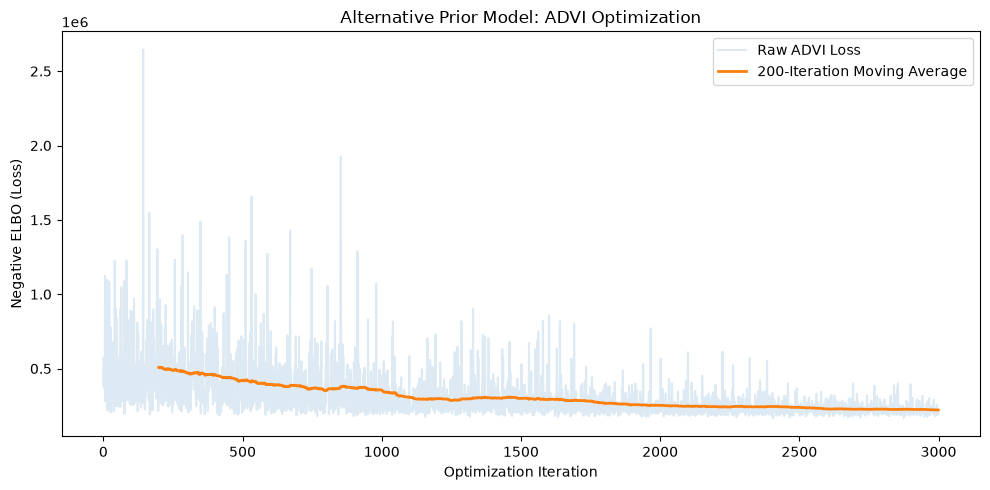


Alternative prior ADVI checks passed.
Posterior accuracy is not yet established.


In [ ]:

# Step 6: Fit alternative prior model using ADVI

import matplotlib.pyplot as plt

SENSITIVITY_ITERATIONS = 3000

print("Fitting alternative prior model...")
print("Training observations:", len(X_train_bayes))
print("Developer effects:", N_DEVELOPERS)

# Fit using the same ADVI settings as the original model
with sensitivity_model:

    sensitivity_advi = pm.ADVI(
        random_seed=config.SEED
    )

    sensitivity_approx = sensitivity_advi.fit(
        n=SENSITIVITY_ITERATIONS,
        progressbar=True
    )

# Extract optimization history
sensitivity_history = np.asarray(
    sensitivity_advi.hist
)

# Compare the final two 200-iteration windows
previous_mean = np.mean(
    sensitivity_history[-400:-200]
)

latest_mean = np.mean(
    sensitivity_history[-200:]
)

relative_change = (
    (latest_mean - previous_mean)
    / abs(previous_mean) * 100
)

print("\nAlternative Prior ADVI Summary:")
print("Iterations:", len(sensitivity_history))
print("Previous 200 mean loss:", round(previous_mean, 2))
print("Latest 200 mean loss:", round(latest_mean, 2))
print("Relative change (%):", round(relative_change, 2))

# Plot optimization progress
rolling_loss = pd.Series(
    sensitivity_history
).rolling(window=200).mean()

plt.figure(figsize=(10, 5))

plt.plot(
    sensitivity_history,
    alpha=0.15,
    label="Raw ADVI Loss"
)

plt.plot(
    rolling_loss,
    linewidth=2,
    label="200-Iteration Moving Average"
)

plt.xlabel("Optimization Iteration")
plt.ylabel("Negative ELBO (Loss)")
plt.title("Alternative Prior Model: ADVI Optimization")


plt.legend()
plt.tight_layout()
plt.savefig(
    config.FIGURES / "03_q6_alternative_prior_advi.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()


# Validation checks
assert len(sensitivity_history) == SENSITIVITY_ITERATIONS
assert np.isfinite(sensitivity_history).all()

print("\nAlternative prior ADVI checks passed.")
print("Posterior accuracy is not yet established.")


In [ ]:

# Step 6: Compare original and alternative prior models

SENSITIVITY_DRAWS = 300

# Generate approximate posterior draws for alternative model
with sensitivity_model:
    sensitivity_trace = sensitivity_approx.sample(
        draws=SENSITIVITY_DRAWS,
        random_seed=config.SEED,
        return_inferencedata=True
    )

print("Alternative posterior samples generated.")

# Function to extract posterior samples
def extract_samples(trace, parameter):
    values = np.asarray(
        trace.posterior[parameter].values
    )
    return values.reshape(
        (-1,) + values.shape[2:]
    )

# Function to summarize posterior parameters
def summarize_posterior(trace):

    results = []

    # Global parameters
    for parameter in [
        "intercept",
        "sigma_developer",
        "concentration"
    ]:
        values = extract_samples(
            trace, parameter
        ).ravel()

        results.append({
            "Parameter": parameter,
            "Mean": np.mean(values),
            "Lower 5%": np.quantile(values, 0.05),
            "Upper 95%": np.quantile(values, 0.95)
        })

    # Regression coefficients
    beta_samples = extract_samples(
        trace, "beta"
    )

    for i, feature in enumerate(MODEL_FEATURES):

        values = beta_samples[:, i]

        results.append({
            "Parameter": feature,
            "Mean": np.mean(values),
            "Lower 5%": np.quantile(values, 0.05),
            "Upper 95%": np.quantile(values, 0.95)
        })

    return pd.DataFrame(results)


# Summarize both posterior approximations
original_summary = summarize_posterior(
    advi_trace
)

alternative_summary = summarize_posterior(
    sensitivity_trace
)

# Combine results
sensitivity_comparison = original_summary.merge(
    alternative_summary,
    on="Parameter",
    suffixes=("_Original", "_Alternative")
)

# Calculate differences in posterior means
sensitivity_comparison["Mean Difference"] = (
    sensitivity_comparison["Mean_Alternative"]
    - sensitivity_comparison["Mean_Original"]
)

display(sensitivity_comparison.round(4))

# Validation checks
assert len(sensitivity_comparison) == (
    len(MODEL_FEATURES) + 3
)

assert sensitivity_trace.posterior.sizes[
    "draw"
] == SENSITIVITY_DRAWS

assert np.isfinite(
    sensitivity_comparison.select_dtypes(
        include="number"
    ).to_numpy()
).all()

print("\nPrior sensitivity comparison checks passed.")


Alternative posterior samples generated.


,Parameter,Mean_Original,Lower 5%_Original,Upper 95%_Original,Mean_Alternative,Lower 5%_Alternative,Upper 95%_Alternative,Mean Difference
0,intercept,0.5722,-0.2969,1.3972,0.5596,-0.3066,1.3818,-0.0126
1,sigma_developer,0.4858,0.1873,0.9962,0.3265,0.1135,0.7053,-0.1593
2,concentration,17.4149,5.8315,37.1558,12.7820,4.3586,27.0423,-4.6329
3,genre_indie,0.4893,-0.3490,1.3181,0.4753,-0.3599,1.3011,-0.0140
4,genre_casual,0.4519,-0.4891,1.2561,0.4386,-0.4992,1.2400,-0.0133
5,genre_action,0.4205,-0.3527,1.2288,0.4074,-0.3635,1.2134,-0.0131
6,genre_adventure,0.4830,-0.4111,1.3340,0.4664,-0.4246,1.3145,-0.0166
7,genre_simulation,0.3333,-0.6112,1.2246,0.3136,-0.6276,1.2018,-0.0197
8,genre_strategy,0.4035,-0.3842,1.2746,0.3894,-0.3954,1.2574,-0.0140
9,genre_rpg,0.3753,-0.5862,1.1995,0.3572,-0.6011,1.1785,-0.0182



Prior sensitivity comparison checks passed.


### 1.7 Model Comparison

Three models were evaluated using the same 12,711 validation games: the Mean Baseline, Binomial GLM, and Bayesian Hierarchical Beta-Binomial model.

Predictive performance was assessed using Mean Absolute Error (MAE), Root Mean Squared Error (RMSE), and mean prediction bias.

The Mean Baseline achieved the lowest validation errors, with an MAE of 0.1859 and RMSE of 0.2403. The Bayesian Beta-Binomial model performed slightly worse, with an MAE of 0.1867 and RMSE of 0.2479, while the Binomial GLM produced the highest errors of 0.1884 and 0.2615.

The GLM also demonstrated the greatest positive prediction bias (0.0847), compared with 0.0288 for the Bayesian model and 0.0037 for the baseline.

Overall, neither statistical model outperformed the simple baseline under the selected evaluation metrics. The results indicate limited additional predictive benefit from the current predictors and modelling specifications. The Bayesian results should also be interpreted cautiously because posterior estimation relied on ADVI rather than converged MCMC sampling.

In [ ]:

# Step 7: Compare model performance on validation data

# Use the same validation observations for every model
required_columns = [
    "steam_positive_rate",
    "baseline_prediction",
    "glm_prediction",
    "bayes_prediction"
]

# Verify all required columns exist
missing = set(required_columns) - set(val_reception.columns)
assert not missing, f"Missing columns: {missing}"

# Actual observed positive review rates
y_true = val_reception[
    "steam_positive_rate"
].to_numpy(dtype=float)

# Model prediction columns
model_predictions = {
    "Mean Baseline": "baseline_prediction",
    "Binomial GLM": "glm_prediction",
    "Bayesian Beta-Binomial": "bayes_prediction"
}

comparison_results = []

for model_name, prediction_column in model_predictions.items():

    y_pred = val_reception[
        prediction_column
    ].to_numpy(dtype=float)

    # Validate predictions
    assert np.isfinite(y_pred).all()
    assert ((y_pred >= 0) & (y_pred <= 1)).all()

    # Calculate prediction errors
    errors = y_pred - y_true

    mae = np.mean(np.abs(errors))
    rmse = np.sqrt(np.mean(errors ** 2))
    bias = np.mean(errors)

    comparison_results.append({
        "Model": model_name,
        "Validation Games": len(y_true),
        "MAE": mae,
        "RMSE": rmse,
        "Mean Bias": bias
    })

# Construct comparison table
model_comparison = pd.DataFrame(comparison_results)

# Compare against baseline
baseline_mae_value = model_comparison.loc[
    model_comparison["Model"] == "Mean Baseline",
    "MAE"
].iloc[0]

baseline_rmse_value = model_comparison.loc[
    model_comparison["Model"] == "Mean Baseline",
    "RMSE"
].iloc[0]

model_comparison["MAE Difference vs Baseline"] = (
    model_comparison["MAE"] - baseline_mae_value
)

model_comparison["RMSE Difference vs Baseline"] = (
    model_comparison["RMSE"] - baseline_rmse_value
)

print("Model Validation Comparison:")
display(model_comparison.round(4))

# Identify lowest validation errors
best_mae = model_comparison.loc[
    model_comparison["MAE"].idxmin(), "Model"
]

best_rmse = model_comparison.loc[
    model_comparison["RMSE"].idxmin(), "Model"
]

print("\nLowest validation MAE:", best_mae)
print("Lowest validation RMSE:", best_rmse)

# Validation checks
assert len(y_true) == 12711
assert len(model_comparison) == 3

assert (model_comparison["Validation Games"] == 12711).all()

assert np.isfinite(
    model_comparison.select_dtypes(
        include="number"
    ).to_numpy()
).all()

print("\nModel comparison checks passed.")


Model Validation Comparison:


,Model,Validation Games,MAE,RMSE,Mean Bias,MAE Difference vs Baseline,RMSE Difference vs Baseline
0,Mean Baseline,12711,0.1859,0.2403,0.0037,0.0000,0.0000
1,Binomial GLM,12711,0.1884,0.2615,0.0847,0.0026,0.0212
2,Bayesian Beta-Binomial,12711,0.1867,0.2479,0.0288,0.0009,0.0076



Lowest validation MAE: Mean Baseline
Lowest validation RMSE: Mean Baseline

Model comparison checks passed.


### 1.8 Completion-Ratio Modelling

Completion-ratio modelling was conducted using 1,886 training games and 471 validation games that satisfied the predefined eligibility criteria. The outcome measures median Steam playtime relative to HLTB main-story duration rather than actual game completion.

The completion-ratio distribution exhibited extreme positive skewness (23.26), with a median of 0.8106 and a maximum of 93.20. A Gamma GLM with a log link was fitted using 11 predictors after removing one constant variable.

The Gamma GLM achieved an MAE of 0.7915 and RMSE of 1.7355. In comparison, the Median Baseline achieved the lowest initial MAE (0.7504), while the Gamma GLM achieved the lowest RMSE.

Influence diagnostics identified 52 potentially influential games, including several with exceptionally high completion ratios. A sensitivity analysis was therefore conducted by excluding the highest 1% of completion ratios (19 games) from the training data while retaining the full validation sample.

The sensitivity model improved MAE to 0.7404 but increased RMSE to 1.7528 and produced greater negative prediction bias. Several regression coefficients also changed, indicating sensitivity to extreme observations.

Overall, the Gamma GLM provided some predictive improvements over the baselines, but the results depended on the evaluation metric and treatment of extreme observations. These limitations should be considered when interpreting the model's findings.

Completion modelling sample:
Training games: 1886
Validation games: 471

Training completion-ratio summary:


count    1886.0000
mean        1.1824
std         2.6744
min         0.0019
5%          0.1024
25%         0.4235
50%         0.8106
75%         1.2888
90%         2.0675
95%         3.0092
99%         8.0453
max        93.2013
Name: completion_ratio, dtype: float64


Skewness: 23.2559

Top 10 highest completion ratios:


,steam_name,steam_playtime_hours_usable,hltb_main_story,steam_review_count,completion_ratio
44609,Blackberry Honey,564.800000,6.06,627,93.201320
52440,Sakuya Izayoi Gives You Advice And Dabs,1.066667,0.04,2293,26.666667
73645,Always The Same Blue Sky...,13.766667,0.66,239,20.858586
6060,9-nine-:Episode 1,98.566667,4.90,1603,20.115646
28731,Thing-in-Itself,5.716667,0.30,115,19.055556
26921,Dandelion - Wishes brought to you -,115.083333,6.68,770,17.228044
16964,Rot Gut,7.450000,0.44,293,16.931818
48063,Don't Make Love,5.766667,0.40,464,14.416667
76054,River City: Rival Showdown,78.566667,6.26,164,12.550586
46145,Dear RED - Extended,3.833333,0.33,392,11.616162


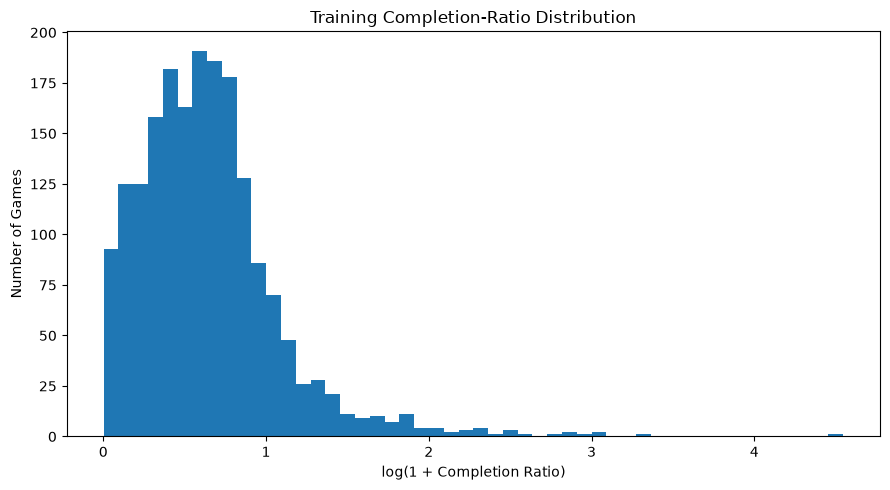


Completion dataset checks passed.


In [ ]:

# Step 8: Inspect completion-ratio modelling data

# Select completion-eligible observations
train_completion = df_train.loc[
    df_train["flag_completion_model"]
].copy()

val_completion = df_val.loc[
    df_val["flag_completion_model"]
].copy()

TARGET_COMPLETION = "completion_ratio"

print("Completion modelling sample:")
print("Training games:", len(train_completion))
print("Validation games:", len(val_completion))

# Check valid positive observations
for dataset in [train_completion, val_completion]:
    target = dataset[TARGET_COMPLETION]

    assert target.notna().all()
    assert np.isfinite(target).all()
    assert target.gt(0).all()

# Inspect training target distribution
print("\nTraining completion-ratio summary:")

display(
    train_completion[TARGET_COMPLETION].describe(
        percentiles=[
            0.05, 0.25, 0.50, 0.75, 0.90, 0.95, 0.99
        ]
    ).round(4)
)

print(
    "\nSkewness:",
    round(train_completion[TARGET_COMPLETION].skew(), 4)
)

# Inspect unusually high ratios
print("\nTop 10 highest completion ratios:")

display(
    train_completion[
        [
            "steam_name",
            "steam_playtime_hours_usable",
            "hltb_main_story",
            "steam_review_count",
            TARGET_COMPLETION
        ]
    ]
    .sort_values(TARGET_COMPLETION, ascending=False)
    .head(10)
)

# Visualize the training distribution
plt.figure(figsize=(9, 5))

plt.hist(
    np.log1p(train_completion[TARGET_COMPLETION]),
    bins=50
)

plt.xlabel("log(1 + Completion Ratio)")
plt.ylabel("Number of Games")
plt.title("Training Completion-Ratio Distribution")

plt.tight_layout()
plt.savefig(
    config.FIGURES / "03_q8_completion_ratio_distribution.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()


# Validate the sample sizes
assert len(train_completion) == 1886
assert len(val_completion) == 471

print("\nCompletion dataset checks passed.")


In [ ]:

# Step 8: Establish completion-ratio baseline models

# Extract training and validation targets
y_train_completion = train_completion[
    TARGET_COMPLETION
].to_numpy(dtype=float)

y_val_completion = val_completion[
    TARGET_COMPLETION
].to_numpy(dtype=float)


# Calculate baseline values from training data only
completion_mean = np.mean(y_train_completion)
completion_median = np.median(y_train_completion)

# Generate constant predictions
mean_predictions = np.full(
    len(y_val_completion),
    completion_mean
)

median_predictions = np.full(
    len(y_val_completion),
    completion_median
)

# Evaluation function
def evaluate_completion(y_true, y_pred):

    errors = y_pred - y_true

    return {
        "MAE": np.mean(np.abs(errors)),
        "RMSE": np.sqrt(np.mean(errors ** 2)),
        "Mean Bias": np.mean(errors)
    }

# Evaluate both baselines
completion_baseline_results = []

for name, predictions in [
    ("Mean Baseline", mean_predictions),
    ("Median Baseline", median_predictions)
]:

    metrics = evaluate_completion(
        y_val_completion,
        predictions
    )

    completion_baseline_results.append({
        "Model": name,
        "Validation Games": len(y_val_completion),
        **metrics
    })

completion_baseline_results = pd.DataFrame(
    completion_baseline_results
)

print("Completion-ratio baseline comparison:")
display(completion_baseline_results.round(4))

print("\nTraining mean:", round(completion_mean, 4))
print("Training median:", round(completion_median, 4))

# Validation checks
assert len(y_train_completion) == 1886
assert len(y_val_completion) == 471

assert np.isfinite(
    completion_baseline_results[
        ["MAE", "RMSE", "Mean Bias"]
    ].to_numpy()
).all()

print("\nCompletion baseline checks passed.")


Completion-ratio baseline comparison:


,Model,Validation Games,MAE,RMSE,Mean Bias
0,Mean Baseline,471,0.8279,1.7751,-0.0006
1,Median Baseline,471,0.7504,1.8137,-0.3724



Training mean: 1.1824
Training median: 0.8106

Completion baseline checks passed.


In [ ]:

# Diagnose rank deficiency in completion model predictors

X_diagnostic = sm.add_constant(
    train_completion[MODEL_FEATURES].astype(float),
    has_constant="add"
)

print("Number of columns:", X_diagnostic.shape[1])
print(
    "Matrix rank:",
    np.linalg.matrix_rank(X_diagnostic.to_numpy())
)

print("\nUnique values per predictor:")
display(
    X_diagnostic.nunique().sort_values()
)

# Identify constant predictors
constant_features = [
    col for col in MODEL_FEATURES
    if X_diagnostic[col].nunique() <= 1
]

print("\nConstant predictors:", constant_features)

print("\nMatrix rank deficiency:",
      X_diagnostic.shape[1]
      - np.linalg.matrix_rank(X_diagnostic.to_numpy()))


Number of columns: 13
Matrix rank: 12

Unique values per predictor:


const                                   1
feature_language_missing                1
genre_casual                            2
genre_indie                             2
genre_adventure                         2
genre_simulation                        2
genre_strategy                          2
genre_action                            2
genre_rpg                               2
flag_missing_genre                      2
feature_game_age                       25
feature_log_language_count_imputed     32
feature_log_price                     183
dtype: int64


Constant predictors: ['feature_language_missing']

Matrix rank deficiency: 1


In [ ]:

# Step 8: Fit Gamma GLM for completion ratios

import statsmodels.api as sm

# Prepare original predictor matrices
X_train_candidate = sm.add_constant(
    train_completion[MODEL_FEATURES].astype(float),
    has_constant="add"
)

X_val_candidate = sm.add_constant(
    val_completion[MODEL_FEATURES].astype(float),
    has_constant="add"
)

X_val_candidate = X_val_candidate[
    X_train_candidate.columns
]

# Identify linearly independent predictors
# Keep the intercept and retain features in original order
selected_columns = []
dropped_columns = []

for col in X_train_candidate.columns:

    candidate_columns = selected_columns + [col]

    candidate_matrix = X_train_candidate[
        candidate_columns
    ].to_numpy()

    if np.linalg.matrix_rank(
        candidate_matrix
    ) == len(candidate_columns):
        selected_columns.append(col)
    else:
        dropped_columns.append(col)

# Use selected predictors for both datasets
X_train_completion = X_train_candidate[
    selected_columns
]

X_val_completion = X_val_candidate[
    selected_columns
]

print("Original predictors:", len(MODEL_FEATURES))
print("Selected predictors:", len(selected_columns) - 1)
print("Dropped redundant predictors:", dropped_columns)

# Verify predictor matrices
assert np.isfinite(
    X_train_completion.to_numpy()
).all()

assert np.isfinite(
    X_val_completion.to_numpy()
).all()

assert np.linalg.matrix_rank(
    X_train_completion.to_numpy()
) == X_train_completion.shape[1]

# Define Gamma GLM with log link
gamma_model = sm.GLM(
    y_train_completion,
    X_train_completion,
    family=sm.families.Gamma(
        link=sm.families.links.Log()
    )
)

# Fit model with robust standard errors
gamma_fit = gamma_model.fit(
    maxiter=200,
    cov_type="HC3"
)

print("\nGamma GLM fitted successfully.")
print("Model converged:", gamma_fit.converged)
print("Training observations:", gamma_fit.nobs)

# Display coefficient estimates
gamma_coefficients = pd.DataFrame({
    "Coefficient": gamma_fit.params,
    "Robust SE": gamma_fit.bse,
    "Exp(Coefficient)": np.exp(gamma_fit.params),
    "P-value": gamma_fit.pvalues
})

display(gamma_coefficients.round(4))

# Generate validation predictions
val_completion["gamma_prediction"] = (
    gamma_fit.predict(X_val_completion)
)

# Evaluate Gamma GLM
gamma_metrics = evaluate_completion(
    y_val_completion,
    val_completion["gamma_prediction"].to_numpy()
)

print("\nGamma GLM validation performance:")

display(
    pd.DataFrame([{
        "Model": "Gamma GLM",
        "Validation Games": len(y_val_completion),
        **gamma_metrics
    }]).round(4)
)

# Validation checks
assert gamma_fit.converged

assert val_completion[
    "gamma_prediction"
].gt(0).all()

assert np.isfinite(
    val_completion["gamma_prediction"]
).all()

print("\nGamma GLM validation checks passed.")


Original predictors: 12
Selected predictors: 11
Dropped redundant predictors: ['feature_language_missing']

Gamma GLM fitted successfully.
Model converged: True
Training observations: 1886


,Coefficient,Robust SE,Exp(Coefficient),P-value
const,0.7974,0.2324,2.2198,0.0006
genre_indie,0.1407,0.1058,1.1511,0.1836
genre_casual,0.2725,0.0954,1.3133,0.0043
genre_action,-0.2871,0.0967,0.7505,0.0030
genre_adventure,-0.0907,0.0756,0.9133,0.2306
genre_simulation,0.2121,0.1042,1.2362,0.0419
genre_strategy,-0.3996,0.1037,0.6706,0.0001
genre_rpg,-0.4070,0.0849,0.6656,0.0000
flag_missing_genre,-0.2544,0.3648,0.7754,0.4856
feature_log_price,-0.0189,0.0673,0.9813,0.7784



Gamma GLM validation performance:


,Model,Validation Games,MAE,RMSE,Mean Bias
0,Gamma GLM,471,0.7915,1.7355,-0.0391



Gamma GLM validation checks passed.


In [ ]:

# Step 8: Compare completion-ratio models

# Add Gamma GLM results to baseline comparison
gamma_result = pd.DataFrame([{
    "Model": "Gamma GLM",
    "Validation Games": len(y_val_completion),
    **gamma_metrics
}])

completion_comparison = pd.concat(
    [completion_baseline_results, gamma_result],
    ignore_index=True
)

# Calculate differences against mean baseline
mean_baseline_mae = completion_comparison.loc[
    completion_comparison["Model"] == "Mean Baseline",
    "MAE"
].iloc[0]

mean_baseline_rmse = completion_comparison.loc[
    completion_comparison["Model"] == "Mean Baseline",
    "RMSE"
].iloc[0]

completion_comparison["MAE Difference vs Mean Baseline"] = (
    completion_comparison["MAE"] - mean_baseline_mae
)

completion_comparison["RMSE Difference vs Mean Baseline"] = (
    completion_comparison["RMSE"] - mean_baseline_rmse
)

print("Completion-Ratio Model Comparison:")
display(completion_comparison.round(4))

# Identify best models
best_mae = completion_comparison.loc[
    completion_comparison["MAE"].idxmin(), "Model"
]

best_rmse = completion_comparison.loc[
    completion_comparison["RMSE"].idxmin(), "Model"
]

print("\nLowest validation MAE:", best_mae)
print("Lowest validation RMSE:", best_rmse)

# Validation checks
assert len(completion_comparison) == 3

assert (
    completion_comparison["Validation Games"] == 471
).all()

assert np.isfinite(
    completion_comparison.select_dtypes(
        include="number"
    ).to_numpy()
).all()

print("\nCompletion model comparison checks passed.")


Completion-Ratio Model Comparison:


,Model,Validation Games,MAE,RMSE,Mean Bias,MAE Difference vs Mean Baseline,RMSE Difference vs Mean Baseline
0,Mean Baseline,471,0.8279,1.7751,-0.0006,0.0000,0.0000
1,Median Baseline,471,0.7504,1.8137,-0.3724,-0.0775,0.0386
2,Gamma GLM,471,0.7915,1.7355,-0.0391,-0.0364,-0.0397



Lowest validation MAE: Median Baseline
Lowest validation RMSE: Gamma GLM

Completion model comparison checks passed.


In [ ]:

# Step 8: Assess influential observations in Gamma GLM

import matplotlib.pyplot as plt

# Calculate influence diagnostics
gamma_influence = gamma_fit.get_influence(
    observed=True
)

# Extract Cook's distance
cooks_distance = gamma_influence.cooks_distance[0]

# Common screening threshold
cooks_threshold = 4 / len(train_completion)

# Prepare influence summary
influence_summary = train_completion[
    ["steam_name", TARGET_COMPLETION]
].copy()

influence_summary["cooks_distance"] = cooks_distance

# Identify potentially influential observations
influence_summary["flag_influential"] = (
    influence_summary["cooks_distance"]
    > cooks_threshold
)

print("Gamma GLM Influence Diagnostics:")
print("Training observations:", len(train_completion))

print(
    "Cook's distance threshold:",
    round(cooks_threshold, 6)
)

print(
    "Potentially influential games:",
    int(influence_summary["flag_influential"].sum())
)

print("\nTop 10 most influential games:")

display(
    influence_summary
    .sort_values("cooks_distance", ascending=False)
    .head(10)
)

# Plot deviance residuals against fitted values
plt.figure(figsize=(9, 5))

plt.scatter(
    gamma_fit.fittedvalues,
    gamma_fit.resid_deviance,
    alpha=0.35,
    s=15
)

plt.axhline(0, linestyle="--")

plt.xlabel("Predicted Completion Ratio")
plt.ylabel("Deviance Residual")
plt.title("Gamma GLM: Deviance Residuals vs Fitted Values")


plt.tight_layout()
plt.savefig(
    config.FIGURES / "03_q8_gamma_deviance_residuals.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()


# Validation
assert len(cooks_distance) == len(train_completion)

assert np.isfinite(cooks_distance).all()

print("\nGamma influence diagnostic checks passed.")


In [ ]:

# Step 8: Sensitivity analysis for extreme completion ratios

# Determine extreme-value threshold from training data only
OUTLIER_PERCENTILE = 0.99

ratio_threshold = train_completion[
    TARGET_COMPLETION
].quantile(OUTLIER_PERCENTILE)

# Retain observations at or below the training threshold
train_completion_sensitivity = train_completion.loc[
    train_completion[TARGET_COMPLETION]
    <= ratio_threshold
].copy()

print("Extreme-value sensitivity analysis")
print("Original training games:", len(train_completion))
print("Sensitivity training games:", len(train_completion_sensitivity))
print(
    "Excluded extreme training games:",
    len(train_completion) - len(train_completion_sensitivity)
)
print("99th percentile threshold:", round(ratio_threshold, 4))

# Use the same predictors as the original Gamma GLM
X_train_sensitivity = sm.add_constant(
    train_completion_sensitivity[
        MODEL_FEATURES
    ].astype(float),
    has_constant="add"
)[selected_columns]

y_train_sensitivity = (
    train_completion_sensitivity[
        TARGET_COMPLETION
    ].to_numpy(dtype=float)
)

# Validate predictor matrix
assert np.linalg.matrix_rank(
    X_train_sensitivity.to_numpy()
) == X_train_sensitivity.shape[1]

# Fit Gamma GLM on sensitivity training sample
gamma_sensitivity_model = sm.GLM(
    y_train_sensitivity,
    X_train_sensitivity,
    family=sm.families.Gamma(
        link=sm.families.links.Log()
    )
)

gamma_sensitivity_fit = gamma_sensitivity_model.fit(
    maxiter=200,
    cov_type="HC3"
)

# Predict on the ORIGINAL complete validation dataset
sensitivity_predictions = gamma_sensitivity_fit.predict(
    X_val_completion
)

# Evaluate using the same 471 validation games
sensitivity_metrics = evaluate_completion(
    y_val_completion,
    sensitivity_predictions
)

# Combine original results and sensitivity model
sensitivity_result = pd.DataFrame([{
    "Model": "Gamma GLM (Top 1% Excluded)",
    "Validation Games": len(y_val_completion),
    **sensitivity_metrics
}])

sensitivity_comparison = pd.concat(
    [
        completion_comparison[
            ["Model", "Validation Games", "MAE", "RMSE", "Mean Bias"]
        ],
        sensitivity_result
    ],
    ignore_index=True
)

print("\nSensitivity Model Comparison:")
display(sensitivity_comparison.round(4))

# Compare regression coefficients
coefficient_comparison = pd.DataFrame({
    "Original Gamma": gamma_fit.params,
    "Sensitivity Gamma": gamma_sensitivity_fit.params
})

coefficient_comparison["Difference"] = (
    coefficient_comparison["Sensitivity Gamma"]
    - coefficient_comparison["Original Gamma"]
)

print("\nCoefficient comparison:")
display(coefficient_comparison.round(4))

# Validation checks
assert gamma_sensitivity_fit.converged
assert len(sensitivity_predictions) == 471
assert np.isfinite(sensitivity_predictions).all()
assert (sensitivity_predictions > 0).all()

print("\nExtreme-value sensitivity checks passed.")


Extreme-value sensitivity analysis
Original training games: 1886
Sensitivity training games: 1867
Excluded extreme training games: 19
99th percentile threshold: 8.0453



Sensitivity Model Comparison:


,Model,Validation Games,MAE,RMSE,Mean Bias
0,Mean Baseline,471,0.8279,1.7751,-0.0006
1,Median Baseline,471,0.7504,1.8137,-0.3724
2,Gamma GLM,471,0.7915,1.7355,-0.0391
3,Gamma GLM (Top 1% Excluded),471,0.7404,1.7528,-0.1979



Coefficient comparison:


,Original Gamma,Sensitivity Gamma,Difference
const,0.7974,0.5874,-0.2101
genre_indie,0.1407,0.1289,-0.0118
genre_casual,0.2725,0.3186,0.0461
genre_action,-0.2871,-0.1989,0.0882
genre_adventure,-0.0907,-0.0936,-0.0029
genre_simulation,0.2121,0.1198,-0.0922
genre_strategy,-0.3996,-0.2424,0.1571
genre_rpg,-0.4070,-0.3557,0.0513
flag_missing_genre,-0.2544,-0.0241,0.2303
feature_log_price,-0.0189,-0.0114,0.0075



Extreme-value sensitivity checks passed.


## Conclusion

This notebook investigated whether Steam game characteristics could predict player reception and completion-related playtime behaviour using frequentist and Bayesian statistical models.

For player reception, the Mean Baseline achieved the lowest validation errors (MAE = 0.1859, RMSE = 0.2403), outperforming both the Binomial GLM and Bayesian Hierarchical Beta-Binomial model. Diagnostic analysis identified severe overdispersion in the Binomial GLM, while the Bayesian model demonstrated imperfect calibration and limitations associated with ADVI posterior approximation.

For completion-ratio modelling, the original Gamma GLM achieved the lowest RMSE (1.7355), while excluding the highest 1% of training completion ratios produced the lowest MAE (0.7404). Sensitivity analysis demonstrated that extreme observations materially influenced predictions and some coefficient estimates.

Overall, the findings suggest that the selected game characteristics provide limited predictive improvements for player reception, while completion-ratio predictions are sensitive to extreme observations. The results should be interpreted as statistical associations rather than causal relationships.

Further evaluation using the original held-out test dataset would be required before drawing conclusions about final out-of-sample performance.

In [ ]:
print("ADVI iterations:", len(advi_inference.hist))

ADVI iterations: 500
